<a href="https://colab.research.google.com/github/scao1828/main/blob/main/ForestHillsStadiumConcerts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import os
import requests
from tqdm import tqdm

# Correct public CloudFront CDN URLs for NYC TLC data
TLC_BASE_URL = "https://d37ci6vzurychx.cloudfront.net/trip-data/"
TAXI_LOOKUP_URL = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"

files_to_download = {
    "taxi_zone_lookup.csv": TAXI_LOOKUP_URL,
    "fhvhv_tripdata_2026-06.parquet": f"{TLC_BASE_URL}fhvhv_tripdata_2026-06.parquet",
    "fhvhv_tripdata_2026-07.parquet": f"{TLC_BASE_URL}fhvhv_tripdata_2026-07.parquet",
    "fhvhv_tripdata_2026-08.parquet": f"{TLC_BASE_URL}fhvhv_tripdata_2026-08.parquet"
}

def download_file(url, destination):
    if os.path.exists(destination):
        print(f"{destination} already exists. Skipping.")
        return

    print(f"Downloading {destination} from {url}...")
    # Include standard User-Agent header to avoid 403 Forbidden/Access Denied errors
    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/115.0.0.0 Safari/537.36"
    }
    response = requests.get(url, headers=headers, stream=True)
    response.raise_for_status()

    total_size = int(response.headers.get('content-length', 0))
    block_size = 1024 * 1024  # 1 MB

    with open(destination, 'wb') as file, tqdm(
        desc=destination,
        total=total_size,
        unit='iB',
        unit_scale=True,
        unit_divisor=1024,
    ) as bar:
        for data in response.iter_content(block_size):
            size = file.write(data)
            bar.update(size)
    print(f"Finished downloading {destination}\n")

for filename, url in files_to_download.items():
    try:
        download_file(url, filename)
    except Exception as e:
        print(f"Error downloading {filename}: {e}")

taxi_zone_lookup.csv: 12.0kiB [00:00, 1.76MiB/s]


Finished downloading taxi_zone_lookup.csv



fhvhv_tripdata_2026-06.parquet: 100%|██████████| 483M/483M [00:07<00:00, 72.3MiB/s]


Finished downloading fhvhv_tripdata_2026-06.parquet



fhvhv_tripdata_2026-07.parquet: 100%|██████████| 487M/487M [00:02<00:00, 218MiB/s]


Finished downloading fhvhv_tripdata_2026-07.parquet



fhvhv_tripdata_2026-08.parquet: 100%|██████████| 479M/479M [00:08<00:00, 62.2MiB/s]

Finished downloading fhvhv_tripdata_2026-08.parquet



In [3]:
import os
import pandas as pd
import plotly.graph_objects as go

# ==========================================
# 1. CONFIGURATION & PARAMETERS
# ==========================================
TAXI_ZONE_LOOKUP_PATH = "taxi_zone_lookup.csv"

FHV_FILES = {
    "June": "fhvhv_tripdata_2026-06.parquet",
    "July": "fhvhv_tripdata_2026-07.parquet",
    "August": "fhvhv_tripdata_2026-08.parquet"
}

# Official 2026 Concert Dates at Forest Hills Stadium for June, July & August
CONCERT_DATES = [
    # June 2026
    "2026-06-06", "2026-06-10", "2026-06-13", "2026-06-19",
    "2026-06-20", "2026-06-27",
    # July 2026
    "2026-07-08", "2026-07-09", "2026-07-11", "2026-07-17",
    "2026-07-18", "2026-07-21", "2026-07-23",
    # August 2026
    "2026-08-15", "2026-08-20", "2026-08-21", "2026-08-22",
    "2026-08-27", "2026-08-28", "2026-08-29"
]
concert_set = set(CONCERT_DATES)

# Time windows
INBOUND_START, INBOUND_END = "17:00:00", "20:30:00"
OUTBOUND_START, OUTBOUND_END = "22:00:00", "00:30:00"
VENUE_ZONE_ID = 95  # Forest Hills Taxi Zone ID

if not os.path.exists(TAXI_ZONE_LOOKUP_PATH):
    raise FileNotFoundError(f"'{TAXI_ZONE_LOOKUP_PATH}' not found in Colab workspace.")

# ==========================================
# 2. DATA PROCESSING WITH MIDNIGHT ADJUSTMENT
# ==========================================
inbound_concert_list = []
outbound_concert_list = []
inbound_control_list = []
outbound_control_list = []

for month, file_path in FHV_FILES.items():
    if not os.path.exists(file_path):
        print(f"Warning: {file_path} not found. Skipping {month}...")
        continue

    print(f"Processing {month} 2026 parquet file...")
    columns = ['pickup_datetime', 'dropoff_datetime', 'PULocationID', 'DOLocationID']
    df = pd.read_parquet(file_path, columns=columns)

    # Parse timestamps
    dt = pd.to_datetime(df['pickup_datetime'])
    dropoff_dt = pd.to_datetime(df['dropoff_datetime'])

    df['calendar_date_str'] = dt.dt.date.astype(str)
    df['pickup_time'] = dt.dt.time.astype(str)
    df['dropoff_time'] = dropoff_dt.dt.time.astype(str)
    df['day_of_week'] = dt.dt.dayofweek

    # FIX: Adjust event date for post-midnight trips (hours 0-3 belong to previous night's event)
    event_dates = dt.dt.date.copy()
    early_morning_mask = dt.dt.hour < 4
    event_dates[early_morning_mask] = (dt[early_morning_mask] - pd.Timedelta(days=1)).dt.date
    df['event_date_str'] = event_dates.astype(str)

    # Identify concert vs non-concert based on event date
    is_concert_event = df['event_date_str'].isin(concert_set)

    # Define filters
    inbound_mask = (df['DOLocationID'] == VENUE_ZONE_ID) & (df['dropoff_time'] >= INBOUND_START) & (df['dropoff_time'] <= INBOUND_END)
    outbound_mask = (df['PULocationID'] == VENUE_ZONE_ID) & (df['pickup_time'] >= OUTBOUND_START) & (df['pickup_time'] <= OUTBOUND_END)

    # 1. Concert Events Data (using event_date_str)
    inbound_concert_list.append(df[is_concert_event & inbound_mask][['event_date_str', 'PULocationID']])
    outbound_concert_list.append(df[is_concert_event & outbound_mask][['event_date_str', 'DOLocationID']])

    # 2. Control Baseline Data
    concert_dow = df[is_concert_event]['day_of_week'].unique()
    control_mask = (~is_concert_event) & (df['day_of_week'].isin(concert_dow))

    inbound_control_list.append(df[control_mask & inbound_mask][['calendar_date_str', 'PULocationID']])
    outbound_control_list.append(df[control_mask & outbound_mask][['calendar_date_str', 'DOLocationID']])

if not inbound_concert_list:
    raise ValueError("No valid data processed.")

in_concert_df = pd.concat(inbound_concert_list, ignore_index=True)
out_concert_df = pd.concat(outbound_concert_list, ignore_index=True)
in_control_df = pd.concat(inbound_control_list, ignore_index=True)
out_control_df = pd.concat(outbound_control_list, ignore_index=True)

num_concert_days = len(concert_set)
num_control_days = in_control_df['calendar_date_str'].nunique() if not in_control_df.empty else 1

# ==========================================
# 3. AGGREGATION & NET EVENT DELTA
# ==========================================
# Inbound
in_concert_agg = in_concert_df.groupby('PULocationID').size().reset_index(name='concert_trips')
in_control_agg = in_control_df.groupby('PULocationID').size().reset_index(name='control_trips') if not in_control_df.empty else pd.DataFrame(columns=['PULocationID', 'control_trips'])

in_merged = pd.merge(in_concert_agg, in_control_agg, on='PULocationID', how='left').fillna(0)
in_merged['baseline_avg_per_day'] = in_merged['control_trips'] / max(num_control_days, 1)
in_merged['net_event_trips'] = (in_merged['concert_trips'] - (in_merged['baseline_avg_per_day'] * num_concert_days)).clip(lower=0)

# Outbound
out_concert_agg = out_concert_df.groupby('DOLocationID').size().reset_index(name='concert_trips')
out_control_agg = out_control_df.groupby('DOLocationID').size().reset_index(name='control_trips') if not out_control_df.empty else pd.DataFrame(columns=['DOLocationID', 'control_trips'])

out_merged = pd.merge(out_concert_agg, out_control_agg, on='DOLocationID', how='left').fillna(0)
out_merged['baseline_avg_per_day'] = out_merged['control_trips'] / max(num_control_days, 1)
out_merged['net_event_trips'] = (out_merged['concert_trips'] - (out_merged['baseline_avg_per_day'] * num_concert_days)).clip(lower=0)

# Load Taxi Zone Names
zone_lookup = pd.read_csv(TAXI_ZONE_LOOKUP_PATH)
zone_dict = dict(zip(zone_lookup['LocationID'], zone_lookup['Zone']))

in_merged['Neighborhood'] = in_merged['PULocationID'].map(zone_dict)
out_merged['Neighborhood'] = out_merged['DOLocationID'].map(zone_dict)

top_origins = in_merged.sort_values(by='net_event_trips', ascending=False).head(10)
top_destinations = out_merged.sort_values(by='net_event_trips', ascending=False).head(10)

# ==========================================
# 4. SANKEY DIAGRAM CONSTRUCTION
# ==========================================
origins = top_origins['Neighborhood'].tolist()
venue = ["Forest Hills Stadium"]
destinations = top_destinations['Neighborhood'].tolist()

all_nodes = origins + venue + destinations
node_mapping = {name: i for i, name in enumerate(all_nodes)}
venue_idx = node_mapping["Forest Hills Stadium"]

sources, targets, values = [], [], []

# Inbound Links
for _, row in top_origins.iterrows():
    sources.append(node_mapping[row['Neighborhood']])
    targets.append(venue_idx)
    values.append(round(row['net_event_trips']))

# Outbound Links
for _, row in top_destinations.iterrows():
    sources.append(venue_idx)
    targets.append(node_mapping[row['Neighborhood']])
    values.append(round(row['net_event_trips']))

fig = go.Figure(data=[go.Sankey(
    node = dict(
      pad = 15,
      thickness = 20,
      line = dict(color = "black", width = 0.5),
      label = all_nodes,
      color = ["skyblue"] * len(origins) + ["orange"] + ["lightgreen"] * len(destinations)
    ),
    link = dict(
      source = sources,
      target = targets,
      value  = values
    )
)])

fig.update_layout(
    title_text="<b>Forest Hills Stadium Net Rideshare Flow (Baseline Adjusted)</b><br>Isolated Concert Impact (July - August 2026)",
    font_size=12,
    width=1100,
    height=750
)

output_filename = "forest_hills_2026_jul_aug_sankey.html"
fig.write_html(output_filename)
print(f"Success! Outbound and inbound flows captured. Saved to '{output_filename}'.")

Processing June 2026 parquet file...
Processing July 2026 parquet file...
Processing August 2026 parquet file...
Success! Outbound and inbound flows captured. Saved to 'forest_hills_2026_jul_aug_sankey.html'.


In [4]:
from google.colab import files
files.download("forest_hills_2026_jul_aug_sankey.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
import os
import pandas as pd
import plotly.graph_objects as go

# ==========================================
# 1. CONFIGURATION & PARAMETERS
# ==========================================
FHV_FILES = {
    "July": "fhvhv_tripdata_2026-07.parquet",
    "August": "fhvhv_tripdata_2026-08.parquet"
}

CONCERT_DATES = [
    "2026-07-08", "2026-07-11", "2026-07-17",
    "2026-07-18", "2026-07-21", "2026-07-23",
    "2026-08-16", "2026-08-20", "2026-08-21",
    "2026-08-22", "2026-08-27", "2026-08-28", "2026-08-29"
]
concert_set = set(CONCERT_DATES)
VENUE_ZONE_ID = 95  # Forest Hills Zone

# ==========================================
# 2. EXTRACT & AGGREGATE INBOUND HOURLY DATA
# ==========================================
concert_hourly_list = []
control_hourly_list = []

for month, file_path in FHV_FILES.items():
    if not os.path.exists(file_path):
        print(f"Warning: {file_path} not found. Skipping {month}...")
        continue

    print(f"Processing hourly inbound data for {month} 2026...")
    df = pd.read_parquet(file_path, columns=['dropoff_datetime', 'DOLocationID'])

    # Filter for arrivals into Forest Hills
    df = df[df['DOLocationID'] == VENUE_ZONE_ID].copy()

    dt = pd.to_datetime(df['dropoff_datetime'])
    df['date_str'] = dt.dt.date.astype(str)
    df['hour'] = dt.dt.hour
    df['day_of_week'] = dt.dt.dayofweek

    is_concert = df['date_str'].isin(concert_set)

    # Collect concert arrivals
    concert_hourly_list.append(df[is_concert][['date_str', 'hour']])

    # Collect baseline control arrivals (matching same days of week)
    concert_dow = df[is_concert]['day_of_week'].unique()
    control_mask = (~is_concert) & (df['day_of_week'].isin(concert_dow))
    control_hourly_list.append(df[control_mask][['date_str', 'hour']])

# Combine datasets
concert_df = pd.concat(concert_hourly_list, ignore_index=True)
control_df = pd.concat(control_hourly_list, ignore_index=True)

num_concert_days = len(concert_set)
num_control_days = control_df['date_str'].nunique() if not control_df.empty else 1

# Calculate average trips per hour per day to normalize comparison
concert_freq = concert_df.groupby('hour').size().reset_index(name='total_trips')
concert_freq['avg_freq'] = concert_freq['total_trips'] / num_concert_days

control_freq = control_df.groupby('hour').size().reset_index(name='total_trips')
control_freq['avg_freq'] = control_freq['total_trips'] / num_control_days

# Merge into a single plotting dataframe
hours_range = pd.DataFrame({'hour': range(24)})
plot_df = hours_range.merge(concert_freq[['hour', 'avg_freq']], on='hour', how='left')\
                     .merge(control_freq[['hour', 'avg_freq']], on='hour', suffixes=('_concert', '_baseline'), how='fillna' if hasattr(pd, 'fillna') else 'left').fillna(0)

# ==========================================
# 3. PLOT HOURLY FREQUENCY LINE CHART
# ==========================================
fig = go.Figure()

# Baseline Control Line
fig.add_trace(go.Scatter(
    x=plot_df['hour'],
    y=plot_df['avg_freq_baseline'],
    mode='lines+markers',
    name='Baseline (Non-Concert Match)',
    line=dict(color='gray', dash='dash', width=2)
))

# Concert Days Line
fig.add_trace(go.Scatter(
    x=plot_df['hour'],
    y=plot_df['avg_freq_concert'],
    mode='lines+markers',
    name='Concert Days (Forest Hills Stadium)',
    line=dict(color='orange', width=4)
))

fig.update_layout(
    title="<b>Inbound Rideshare Frequency to Forest Hills (Zone 95)</b><br>Hourly Average Drop-offs: Concert Days vs. Baseline",
    xaxis_title="Hour of Day (0 = Midnight, 23 = 11 PM)",
    yaxis_title="Average Trips per Day",
    xaxis=dict(tickmode='linear', dtick=1),
    font_size=12,
    width=1000,
    height=600
)

output_filename = "forest_hills_inbound_frequency_chart.html"
fig.write_html(output_filename)
print(f"Success! Frequency chart generated and saved to '{output_filename}'.")

Processing hourly inbound data for July 2026...
Processing hourly inbound data for August 2026...
Success! Frequency chart generated and saved to 'forest_hills_inbound_frequency_chart.html'.


In [6]:
import os
import pandas as pd
import plotly.graph_objects as go

# ==========================================
# 1. CONFIGURATION & PARAMETERS
# ==========================================
TAXI_ZONE_LOOKUP_PATH = "taxi_zone_lookup.csv"

FHV_FILES = {
    "June": "fhvhv_tripdata_2026-06.parquet",
    "July": "fhvhv_tripdata_2026-07.parquet",
    "August": "fhvhv_tripdata_2026-08.parquet"
}

# Official 2026 Concert Dates at Forest Hills Stadium for June, July & August
CONCERT_DATES = [
    # June 2026
    "2026-06-06", "2026-06-10", "2026-06-13", "2026-06-19",
    "2026-06-20", "2026-06-27",
    # July 2026
    "2026-07-08", "2026-07-09", "2026-07-11", "2026-07-17",
    "2026-07-18", "2026-07-21", "2026-07-23",
    # August 2026
    "2026-08-15", "2026-08-20", "2026-08-21", "2026-08-22",
    "2026-08-27", "2026-08-28", "2026-08-29"
]
concert_set = set(CONCERT_DATES)

# Time windows
INBOUND_START, INBOUND_END = "17:00:00", "20:30:00"
OUTBOUND_START, OUTBOUND_END = "22:00:00", "00:30:00"
VENUE_ZONE_ID = 95  # Forest Hills Taxi Zone ID

if not os.path.exists(TAXI_ZONE_LOOKUP_PATH):
    raise FileNotFoundError(f"'{TAXI_ZONE_LOOKUP_PATH}' not found in Colab workspace.")

# ==========================================
# 2. DATA PROCESSING WITH MIDNIGHT ADJUSTMENT
# ==========================================
inbound_concert_list = []
outbound_concert_list = []
inbound_control_list = []
outbound_control_list = []

for month, file_path in FHV_FILES.items():
    if not os.path.exists(file_path):
        print(f"Warning: {file_path} not found. Skipping {month}...")
        continue

    print(f"Processing {month} 2026 parquet file...")
    columns = ['pickup_datetime', 'dropoff_datetime', 'PULocationID', 'DOLocationID']
    df = pd.read_parquet(file_path, columns=columns)

    # Parse timestamps
    dt = pd.to_datetime(df['pickup_datetime'])
    dropoff_dt = pd.to_datetime(df['dropoff_datetime'])

    df['calendar_date_str'] = dt.dt.date.astype(str)
    df['pickup_time'] = dt.dt.time.astype(str)
    df['dropoff_time'] = dropoff_dt.dt.time.astype(str)
    df['day_of_week'] = dt.dt.dayofweek

    # FIX: Adjust event date for post-midnight trips (hours 0-3 belong to previous night's event)
    event_dates = dt.dt.date.copy()
    early_morning_mask = dt.dt.hour < 4
    event_dates[early_morning_mask] = (dt[early_morning_mask] - pd.Timedelta(days=1)).dt.date
    df['event_date_str'] = event_dates.astype(str)

    # Identify concert vs non-concert based on event date
    is_concert_event = df['event_date_str'].isin(concert_set)

    # Define filters
    inbound_mask = (df['DOLocationID'] == VENUE_ZONE_ID) & (df['dropoff_time'] >= INBOUND_START) & (df['dropoff_time'] <= INBOUND_END)
    outbound_mask = (df['PULocationID'] == VENUE_ZONE_ID) & (df['pickup_time'] >= OUTBOUND_START) & (df['pickup_time'] <= OUTBOUND_END)

    # 1. Concert Events Data (using event_date_str)
    inbound_concert_list.append(df[is_concert_event & inbound_mask][['event_date_str', 'PULocationID']])
    outbound_concert_list.append(df[is_concert_event & outbound_mask][['event_date_str', 'DOLocationID']])

    # 2. Control Baseline Data
    concert_dow = df[is_concert_event]['day_of_week'].unique()
    control_mask = (~is_concert_event) & (df['day_of_week'].isin(concert_dow))

    inbound_control_list.append(df[control_mask & inbound_mask][['calendar_date_str', 'PULocationID']])
    outbound_control_list.append(df[control_mask & outbound_mask][['calendar_date_str', 'DOLocationID']])

if not inbound_concert_list:
    raise ValueError("No valid data processed.")

in_concert_df = pd.concat(inbound_concert_list, ignore_index=True)
out_concert_df = pd.concat(outbound_concert_list, ignore_index=True)
in_control_df = pd.concat(inbound_control_list, ignore_index=True)
out_control_df = pd.concat(outbound_control_list, ignore_index=True)

num_concert_days = len(concert_set)
num_control_days = in_control_df['calendar_date_str'].nunique() if not in_control_df.empty else 1

# ==========================================
# 3. AGGREGATION & NET EVENT DELTA
# ==========================================
# Inbound
in_concert_agg = in_concert_df.groupby('PULocationID').size().reset_index(name='concert_trips')
in_control_agg = in_control_df.groupby('PULocationID').size().reset_index(name='control_trips') if not in_control_df.empty else pd.DataFrame(columns=['PULocationID', 'control_trips'])

in_merged = pd.merge(in_concert_agg, in_control_agg, on='PULocationID', how='left').fillna(0)
in_merged['baseline_avg_per_day'] = in_merged['control_trips'] / max(num_control_days, 1)
in_merged['net_event_trips'] = (in_merged['concert_trips'] - (in_merged['baseline_avg_per_day'] * num_concert_days)).clip(lower=0)

# Outbound
out_concert_agg = out_concert_df.groupby('DOLocationID').size().reset_index(name='concert_trips')
out_control_agg = out_control_df.groupby('DOLocationID').size().reset_index(name='control_trips') if not out_control_df.empty else pd.DataFrame(columns=['DOLocationID', 'control_trips'])

out_merged = pd.merge(out_concert_agg, out_control_agg, on='DOLocationID', how='left').fillna(0)
out_merged['baseline_avg_per_day'] = out_merged['control_trips'] / max(num_control_days, 1)
out_merged['net_event_trips'] = (out_merged['concert_trips'] - (out_merged['baseline_avg_per_day'] * num_concert_days)).clip(lower=0)

# Load Taxi Zone Names
zone_lookup = pd.read_csv(TAXI_ZONE_LOOKUP_PATH)
zone_dict = dict(zip(zone_lookup['LocationID'], zone_lookup['Zone']))

in_merged['Neighborhood'] = in_merged['PULocationID'].map(zone_dict)
out_merged['Neighborhood'] = out_merged['DOLocationID'].map(zone_dict)

top_origins = in_merged.sort_values(by='net_event_trips', ascending=False).head(10)
top_destinations = out_merged.sort_values(by='net_event_trips', ascending=False).head(10)

# ==========================================
# 4. SANKEY DIAGRAM CONSTRUCTION
# ==========================================
origins = top_origins['Neighborhood'].tolist()
venue = ["Forest Hills Stadium"]
destinations = top_destinations['Neighborhood'].tolist()

all_nodes = origins + venue + destinations
node_mapping = {name: i for i, name in enumerate(all_nodes)}
venue_idx = node_mapping["Forest Hills Stadium"]

sources, targets, values = [], [], []

# Inbound Links
for _, row in top_origins.iterrows():
    sources.append(node_mapping[row['Neighborhood']])
    targets.append(venue_idx)
    values.append(round(row['net_event_trips']))

# Outbound Links
for _, row in top_destinations.iterrows():
    sources.append(venue_idx)
    targets.append(node_mapping[row['Neighborhood']])
    values.append(round(row['net_event_trips']))

fig = go.Figure(data=[go.Sankey(
    node = dict(
      pad = 15,
      thickness = 20,
      line = dict(color = "black", width = 0.5),
      label = all_nodes,
      color = ["skyblue"] * len(origins) + ["orange"] + ["lightgreen"] * len(destinations)
    ),
    link = dict(
      source = sources,
      target = targets,
      value  = values
    )
)])

fig.update_layout(
    title_text="<b>Forest Hills Stadium Net Rideshare Flow (Baseline Adjusted)</b><br>Isolated Concert Impact (July - August 2026)",
    font_size=12,
    width=1100,
    height=750
)

output_filename = "forest_hills_2026_jul_aug_sankey.html"
fig.write_html(output_filename)
print(f"Success! Outbound and inbound flows captured. Saved to '{output_filename}'.")

Processing June 2026 parquet file...
Processing July 2026 parquet file...
Processing August 2026 parquet file...
Success! Outbound and inbound flows captured. Saved to 'forest_hills_2026_jul_aug_sankey.html'.


In [7]:
from google.colab import files
files.download("forest_hills_inbound_frequency_chart.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

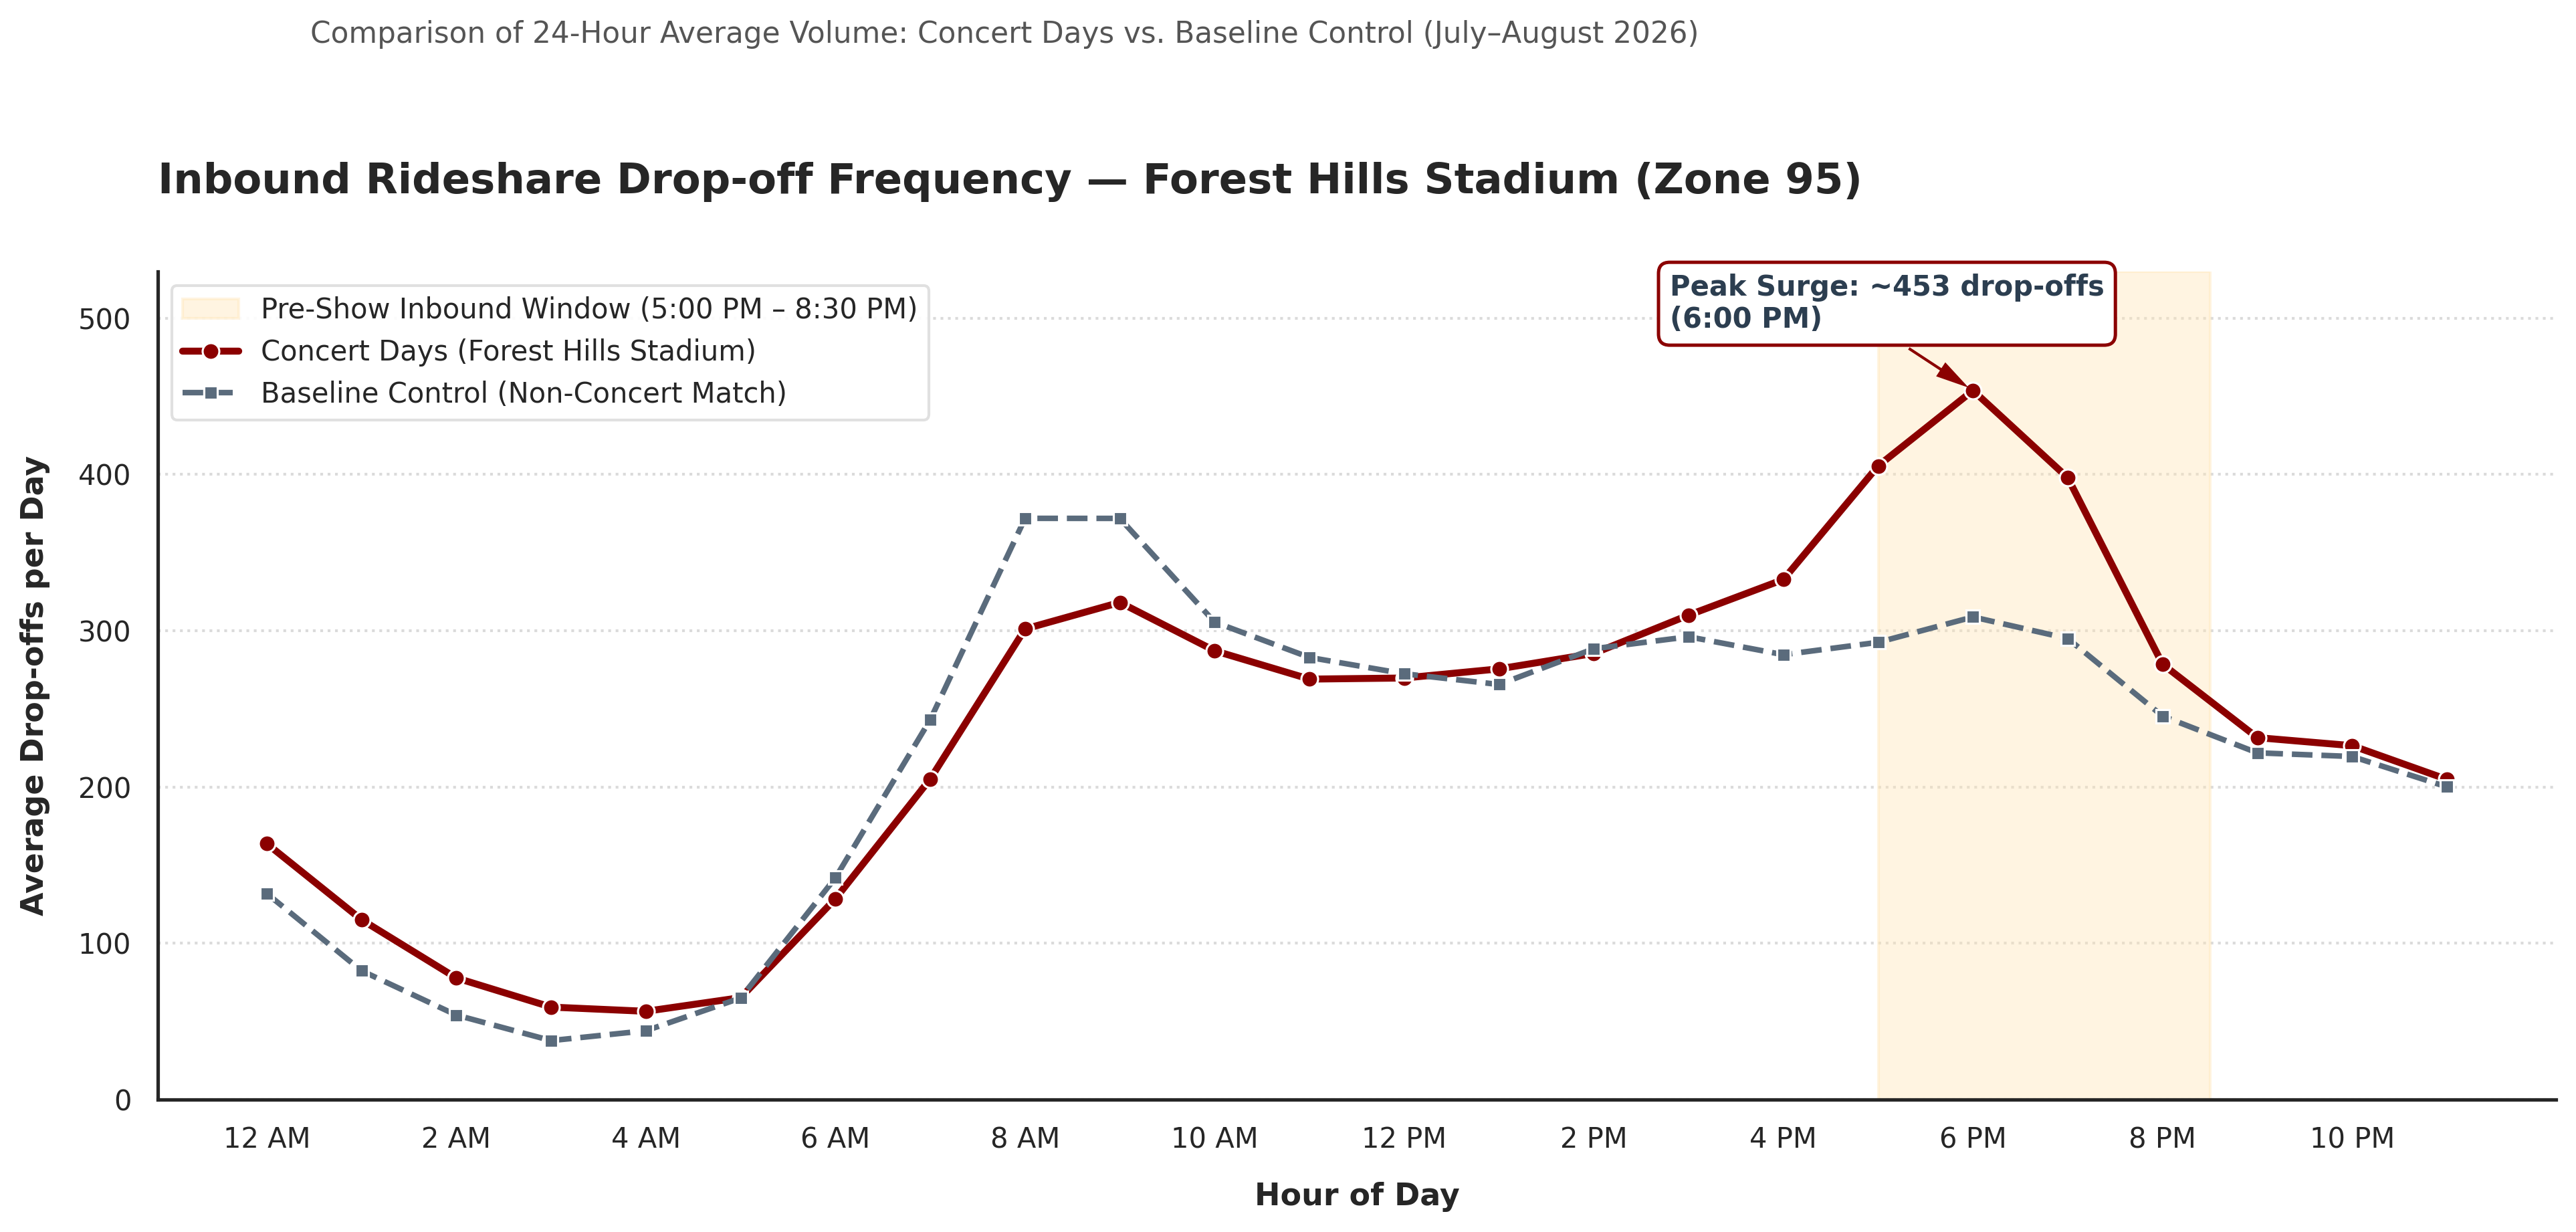

In [8]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. CONFIGURATION & PARAMETERS
# ==========================================
FFHV_FILES = {
    "June": "fhvhv_tripdata_2026-06.parquet",
    "July": "fhvhv_tripdata_2026-07.parquet",
    "August": "fhvhv_tripdata_2026-08.parquet"
}

# Official 2026 Concert Dates at Forest Hills Stadium for June, July & August
CONCERT_DATES = [
    # June 2026
    "2026-06-06", "2026-06-10", "2026-06-13", "2026-06-19",
    "2026-06-20", "2026-06-27",
    # July 2026
    "2026-07-08", "2026-07-09", "2026-07-11", "2026-07-17",
    "2026-07-18", "2026-07-21", "2026-07-23",
    # August 2026
    "2026-08-15", "2026-08-20", "2026-08-21", "2026-08-22",
    "2026-08-27", "2026-08-28", "2026-08-29"
]
concert_set = set(CONCERT_DATES)
VENUE_ZONE_ID = 95  # Forest Hills Zone

inbound_concert_list, inbound_control_list = [], []

# ==========================================
# 2. DATA EXTRACTION & AGGREGATION
# ==========================================
for month, file_path in FHV_FILES.items():
    if not os.path.exists(file_path):
        print(f"Warning: {file_path} not found. Skipping {month}...")
        continue

    df = pd.read_parquet(file_path, columns=['dropoff_datetime', 'DOLocationID'])
    df = df[df['DOLocationID'] == VENUE_ZONE_ID].copy()

    dropoff_dt = pd.to_datetime(df['dropoff_datetime'])
    df['dropoff_date_str'] = dropoff_dt.dt.date.astype(str)
    df['dropoff_hour'] = dropoff_dt.dt.hour
    df['dropoff_dow'] = dropoff_dt.dt.dayofweek

    is_concert = df['dropoff_date_str'].isin(concert_set)
    inbound_concert_list.append(df[is_concert][['dropoff_date_str', 'dropoff_hour']])

    concert_dow = df[is_concert]['dropoff_dow'].unique()
    control_mask = (~is_concert) & (df['dropoff_dow'].isin(concert_dow))
    inbound_control_list.append(df[control_mask][['dropoff_date_str', 'dropoff_hour']])

in_c_df = pd.concat(inbound_concert_list, ignore_index=True)
in_ctl_df = pd.concat(inbound_control_list, ignore_index=True)

num_concert_days = len(concert_set)
num_ctl_days = in_ctl_df['dropoff_date_str'].nunique() if not in_ctl_df.empty else 1

in_c_freq = in_c_df.groupby('dropoff_hour').size().reset_index(name='trips')
in_c_freq['avg'] = in_c_freq['trips'] / num_concert_days

in_ctl_freq = in_ctl_df.groupby('dropoff_hour').size().reset_index(name='trips')
in_ctl_freq['avg'] = in_ctl_freq['trips'] / max(num_ctl_days, 1)

plot_df = pd.DataFrame({'hour': range(24)}).merge(in_c_freq[['dropoff_hour', 'avg']], left_on='hour', right_on='dropoff_hour', how='left') \
                                          .merge(in_ctl_freq[['dropoff_hour', 'avg']], left_on='hour', right_on='dropoff_hour', suffixes=('_concert', '_baseline'), how='left').fillna(0)

# ==========================================
# 3. PROFESSIONAL PLOTTING
# ==========================================
plt.figure(figsize=(13, 6.8), dpi=300)
sns.set_theme(style="white")

# Color palette definition (Dark Red theme)
concert_color = "#8B0000"   # Dark Red
baseline_color = "#5A6B7C"  # Professional slate gray

# Highlight pre-show window with a soft professional tint
plt.axvspan(17, 20.5, color='#FFE5B4', alpha=0.4, label='Pre-Show Inbound Window (5:00 PM – 8:30 PM)')

# Plot lines
sns.lineplot(data=plot_df, x='hour', y='avg_concert', label='Concert Days (Forest Hills Stadium)',
             color=concert_color, linewidth=2.5, marker='o', markersize=6)
sns.lineplot(data=plot_df, x='hour', y='avg_baseline', label='Baseline Control (Non-Concert Match)',
             color=baseline_color, linewidth=2, linestyle='--', marker='s', markersize=5)

# Give enough headroom on Y-axis to prevent text crowding at the top
plt.ylim(0, 530)

# Annotate Peak Rush Hour (positioned safely below the title)
peak_row = plot_df.loc[plot_df['avg_concert'].idxmax()]
plt.annotate(f"Peak Surge: ~{int(peak_row['avg_concert'])} drop-offs\n(6:00 PM)",
             xy=(peak_row['hour'], peak_row['avg_concert']),
             xytext=(peak_row['hour'] - 3.2, peak_row['avg_concert'] + 40),
             arrowprops=dict(facecolor=concert_color, shrink=0.05, width=1, headwidth=6, edgecolor='none'),
             fontsize=10, fontweight='bold', color='#2C3E50',
             bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=concert_color, lw=1.2))

# Typography and Titles
plt.title("Inbound Rideshare Drop-off Frequency — Forest Hills Stadium (Zone 95)", fontsize=15, fontweight='bold', pad=28, loc='left')
plt.suptitle("Comparison of 24-Hour Average Volume: Concert Days vs. Baseline Control (July–August 2026)", fontsize=10.5, color='#555555', x=0.125, y=0.93, ha='left')

plt.xlabel("Hour of Day", fontsize=11, fontweight='semibold', labelpad=10)
plt.ylabel("Average Drop-offs per Day", fontsize=11, fontweight='semibold', labelpad=10)

# Custom X-axis labels (AM/PM formatting)
hour_labels = ['12 AM', '2 AM', '4 AM', '6 AM', '8 AM', '10 AM', '12 PM',
               '2 PM', '4 PM', '6 PM', '8 PM', '10 PM']
plt.xticks(range(0, 24, 2), hour_labels, fontsize=10)
plt.yticks(fontsize=10)

# Clean grid and styling adjustments
plt.grid(axis='y', linestyle=':', alpha=0.7, color='#CCCCCC')
sns.despine(top=True, right=True)

plt.legend(frameon=True, facecolor='white', edgecolor='#DDDDDD', fontsize=10, loc='upper left', framealpha=0.9)
plt.tight_layout(rect=[0, 0.03, 1, 0.90])

plt.show()

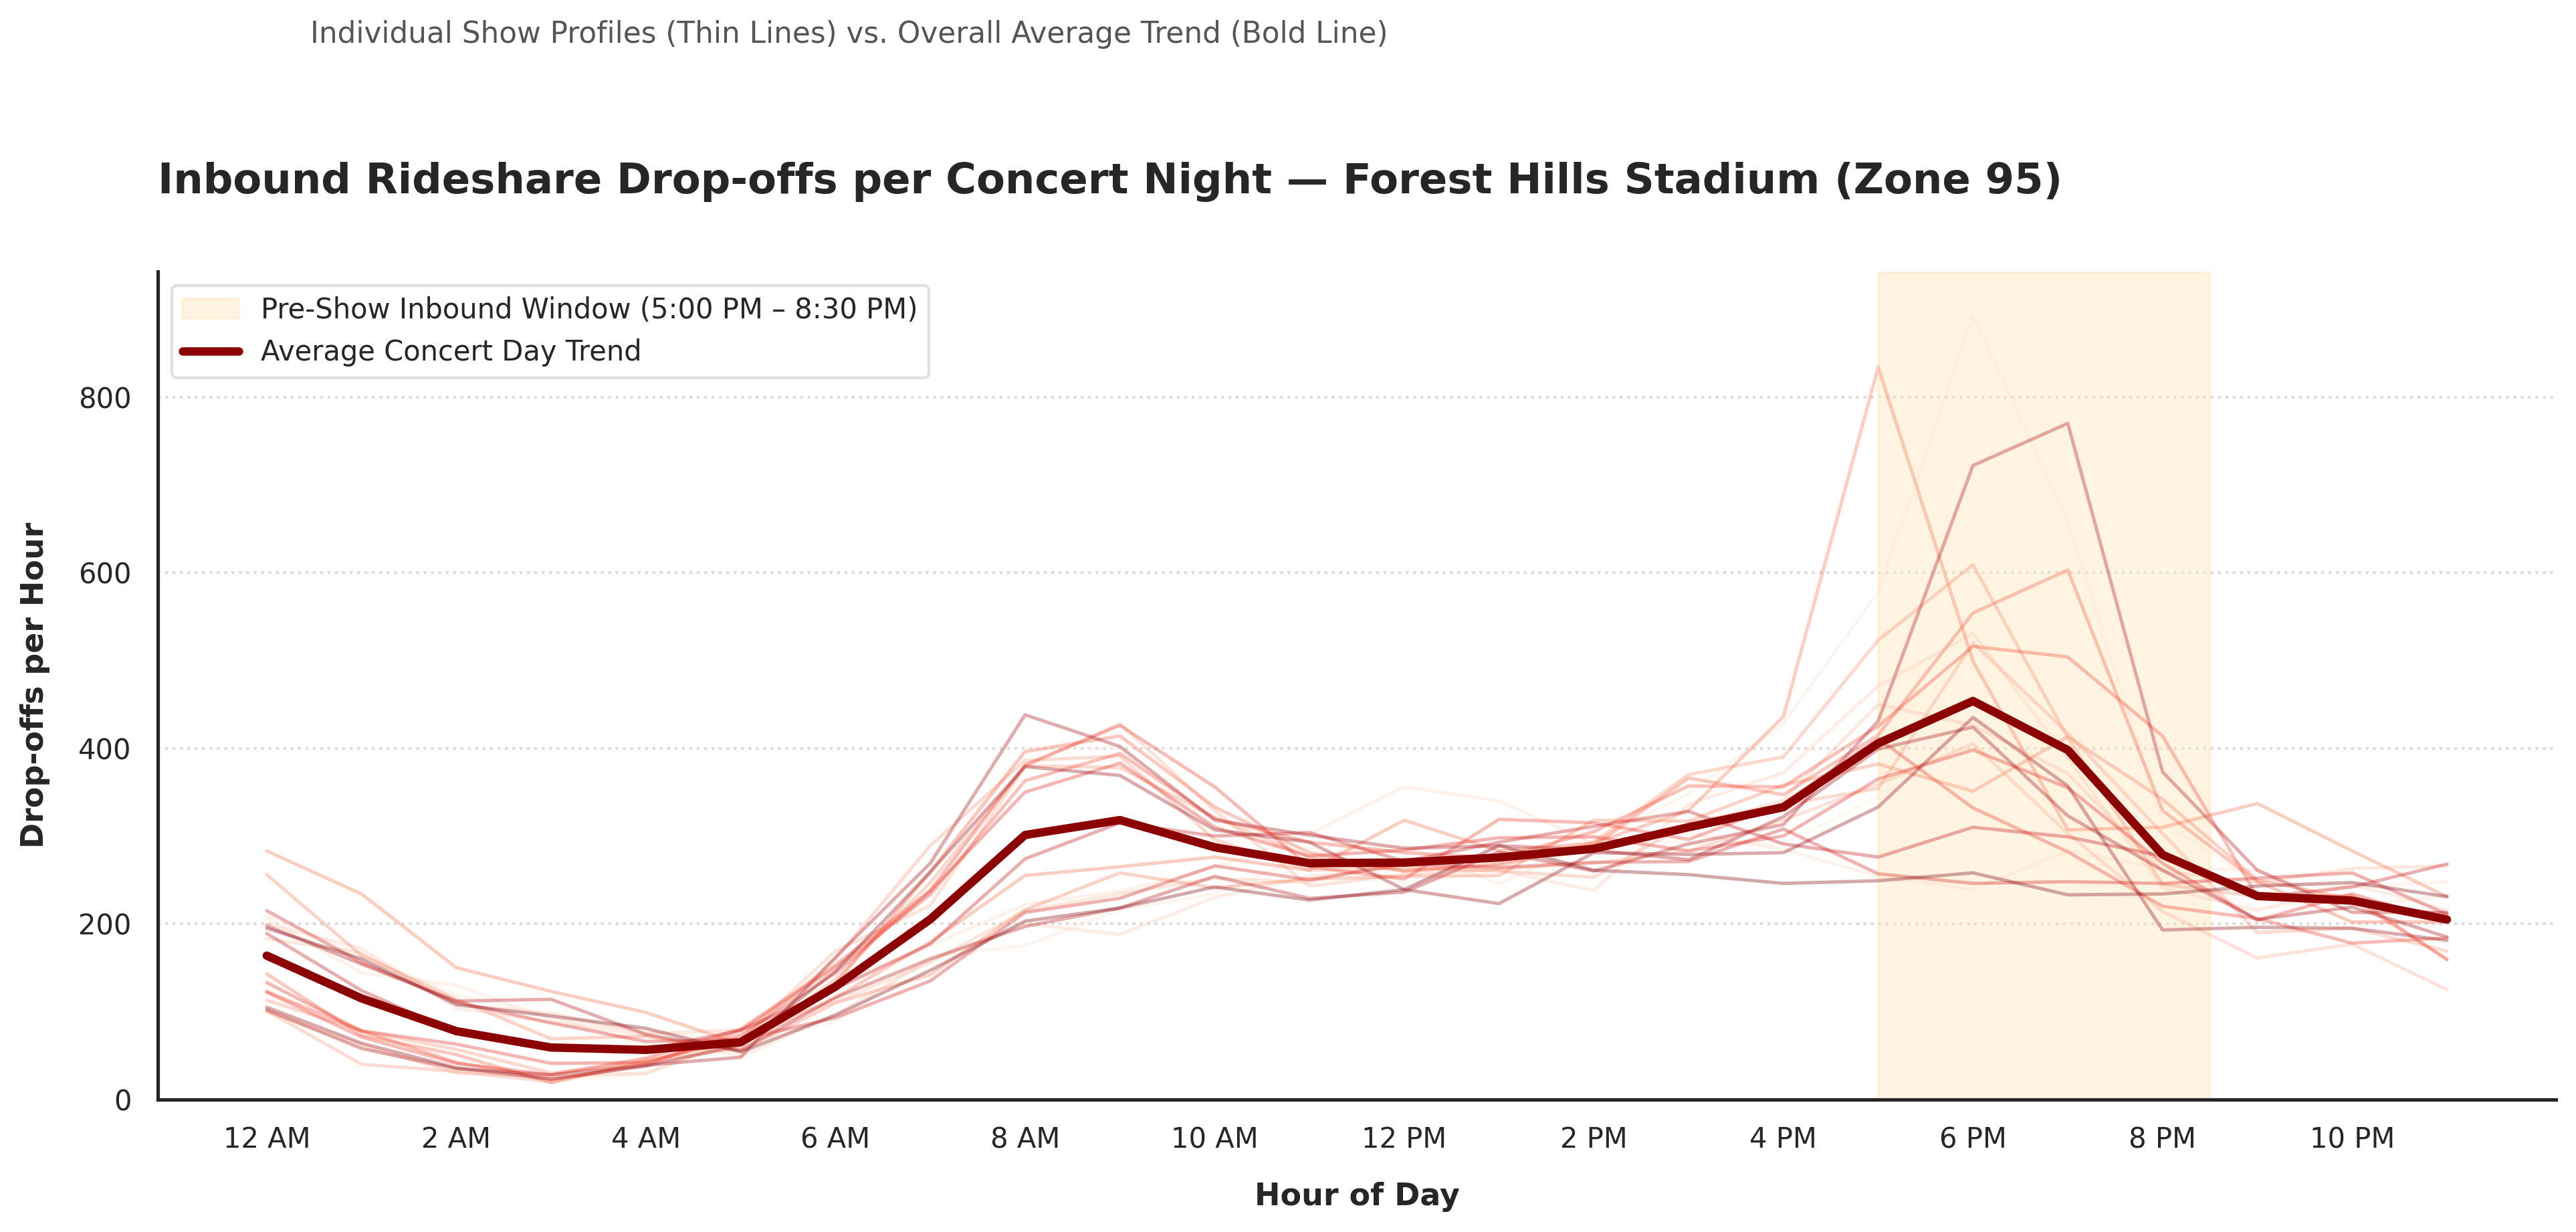

In [9]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. CONFIGURATION & PARAMETERS
# ==========================================
FFHV_FILES = {
    "June": "fhvhv_tripdata_2026-06.parquet",
    "July": "fhvhv_tripdata_2026-07.parquet",
    "August": "fhvhv_tripdata_2026-08.parquet"
}

# Official 2026 Concert Dates at Forest Hills Stadium for June, July & August
CONCERT_DATES = [
    # June 2026
    "2026-06-06", "2026-06-10", "2026-06-13", "2026-06-19",
    "2026-06-20", "2026-06-27",
    # July 2026
    "2026-07-08", "2026-07-09", "2026-07-11", "2026-07-17",
    "2026-07-18", "2026-07-21", "2026-07-23",
    # August 2026
    "2026-08-15", "2026-08-20", "2026-08-21", "2026-08-22",
    "2026-08-27", "2026-08-28", "2026-08-29"
]
concert_set = set(CONCERT_DATES)
VENUE_ZONE_ID = 95  # Forest Hills Zone

inbound_concert_list = []

# ==========================================
# 2. DATA EXTRACTION PER CONCERT DATE
# ==========================================
for month, file_path in FHV_FILES.items():
    if not os.path.exists(file_path):
        print(f"Warning: {file_path} not found. Skipping {month}...")
        continue

    df = pd.read_parquet(file_path, columns=['dropoff_datetime', 'DOLocationID'])
    df = df[df['DOLocationID'] == VENUE_ZONE_ID].copy()

    dropoff_dt = pd.to_datetime(df['dropoff_datetime'])
    df['dropoff_date_str'] = dropoff_dt.dt.date.astype(str)
    df['dropoff_hour'] = dropoff_dt.dt.hour

    is_concert = df['dropoff_date_str'].isin(concert_set)
    inbound_concert_list.append(df[is_concert][['dropoff_date_str', 'dropoff_hour']])

c_df = pd.concat(inbound_concert_list, ignore_index=True)

# Group by date and hour to get trip counts for every single show
df_counts = c_df.groupby(['dropoff_date_str', 'dropoff_hour']).size().reset_index(name='trips')

# Ensure all 24 hours exist for every concert date (fill missing hours with 0 trips)
full_idx = pd.MultiIndex.from_product([list(concert_set), range(24)], names=['dropoff_date_str', 'dropoff_hour'])
df_counts = df_counts.set_index(['dropoff_date_str', 'dropoff_hour']).reindex(full_idx, fill_value=0).reset_index()

# Calculate the mean trend line for reference
mean_df = df_counts.groupby('dropoff_hour')['trips'].mean().reset_index()

# ==========================================
# 3. PROFESSIONAL SPAGHETTI PLOT
# ==========================================
plt.figure(figsize=(13, 6.8), dpi=300)
sns.set_theme(style="white")

# Highlight pre-show window
plt.axvspan(17, 20.5, color='#FFE5B4', alpha=0.4, label='Pre-Show Inbound Window (5:00 PM – 8:30 PM)')

# Plot individual concert dates as thin, transparent lines
sns.lineplot(
    data=df_counts, x='dropoff_hour', y='trips', hue='dropoff_date_str',
    units='dropoff_date_str', estimator=None, palette='Reds', alpha=0.35, linewidth=1.2, legend=False
)

# Plot overall average trend line on top in bold dark red
sns.lineplot(
    data=mean_df, x='dropoff_hour', y='trips', color='#8B0000', linewidth=3, label='Average Concert Day Trend'
)

# Typography and Titles
plt.title("Inbound Rideshare Drop-offs per Concert Night — Forest Hills Stadium (Zone 95)", fontsize=15, fontweight='bold', pad=28, loc='left')
plt.suptitle("Individual Show Profiles (Thin Lines) vs. Overall Average Trend (Bold Line)", fontsize=10.5, color='#555555', x=0.125, y=0.93, ha='left')

plt.xlabel("Hour of Day", fontsize=11, fontweight='semibold', labelpad=10)
plt.ylabel("Drop-offs per Hour", fontsize=11, fontweight='semibold', labelpad=10)

# Custom X-axis labels (AM/PM formatting)
hour_labels = ['12 AM', '2 AM', '4 AM', '6 AM', '8 AM', '10 AM', '12 PM',
               '2 PM', '4 PM', '6 PM', '8 PM', '10 PM']
plt.xticks(range(0, 24, 2), hour_labels, fontsize=10)
plt.yticks(fontsize=10)
plt.ylim(0, max(df_counts['trips']) + 50)

# Clean grid and styling adjustments
plt.grid(axis='y', linestyle=':', alpha=0.7, color='#CCCCCC')
sns.despine(top=True, right=True)

plt.legend(frameon=True, facecolor='white', edgecolor='#DDDDDD', fontsize=10, loc='upper left', framealpha=0.9)
plt.tight_layout(rect=[0, 0.03, 1, 0.90])

plt.show()

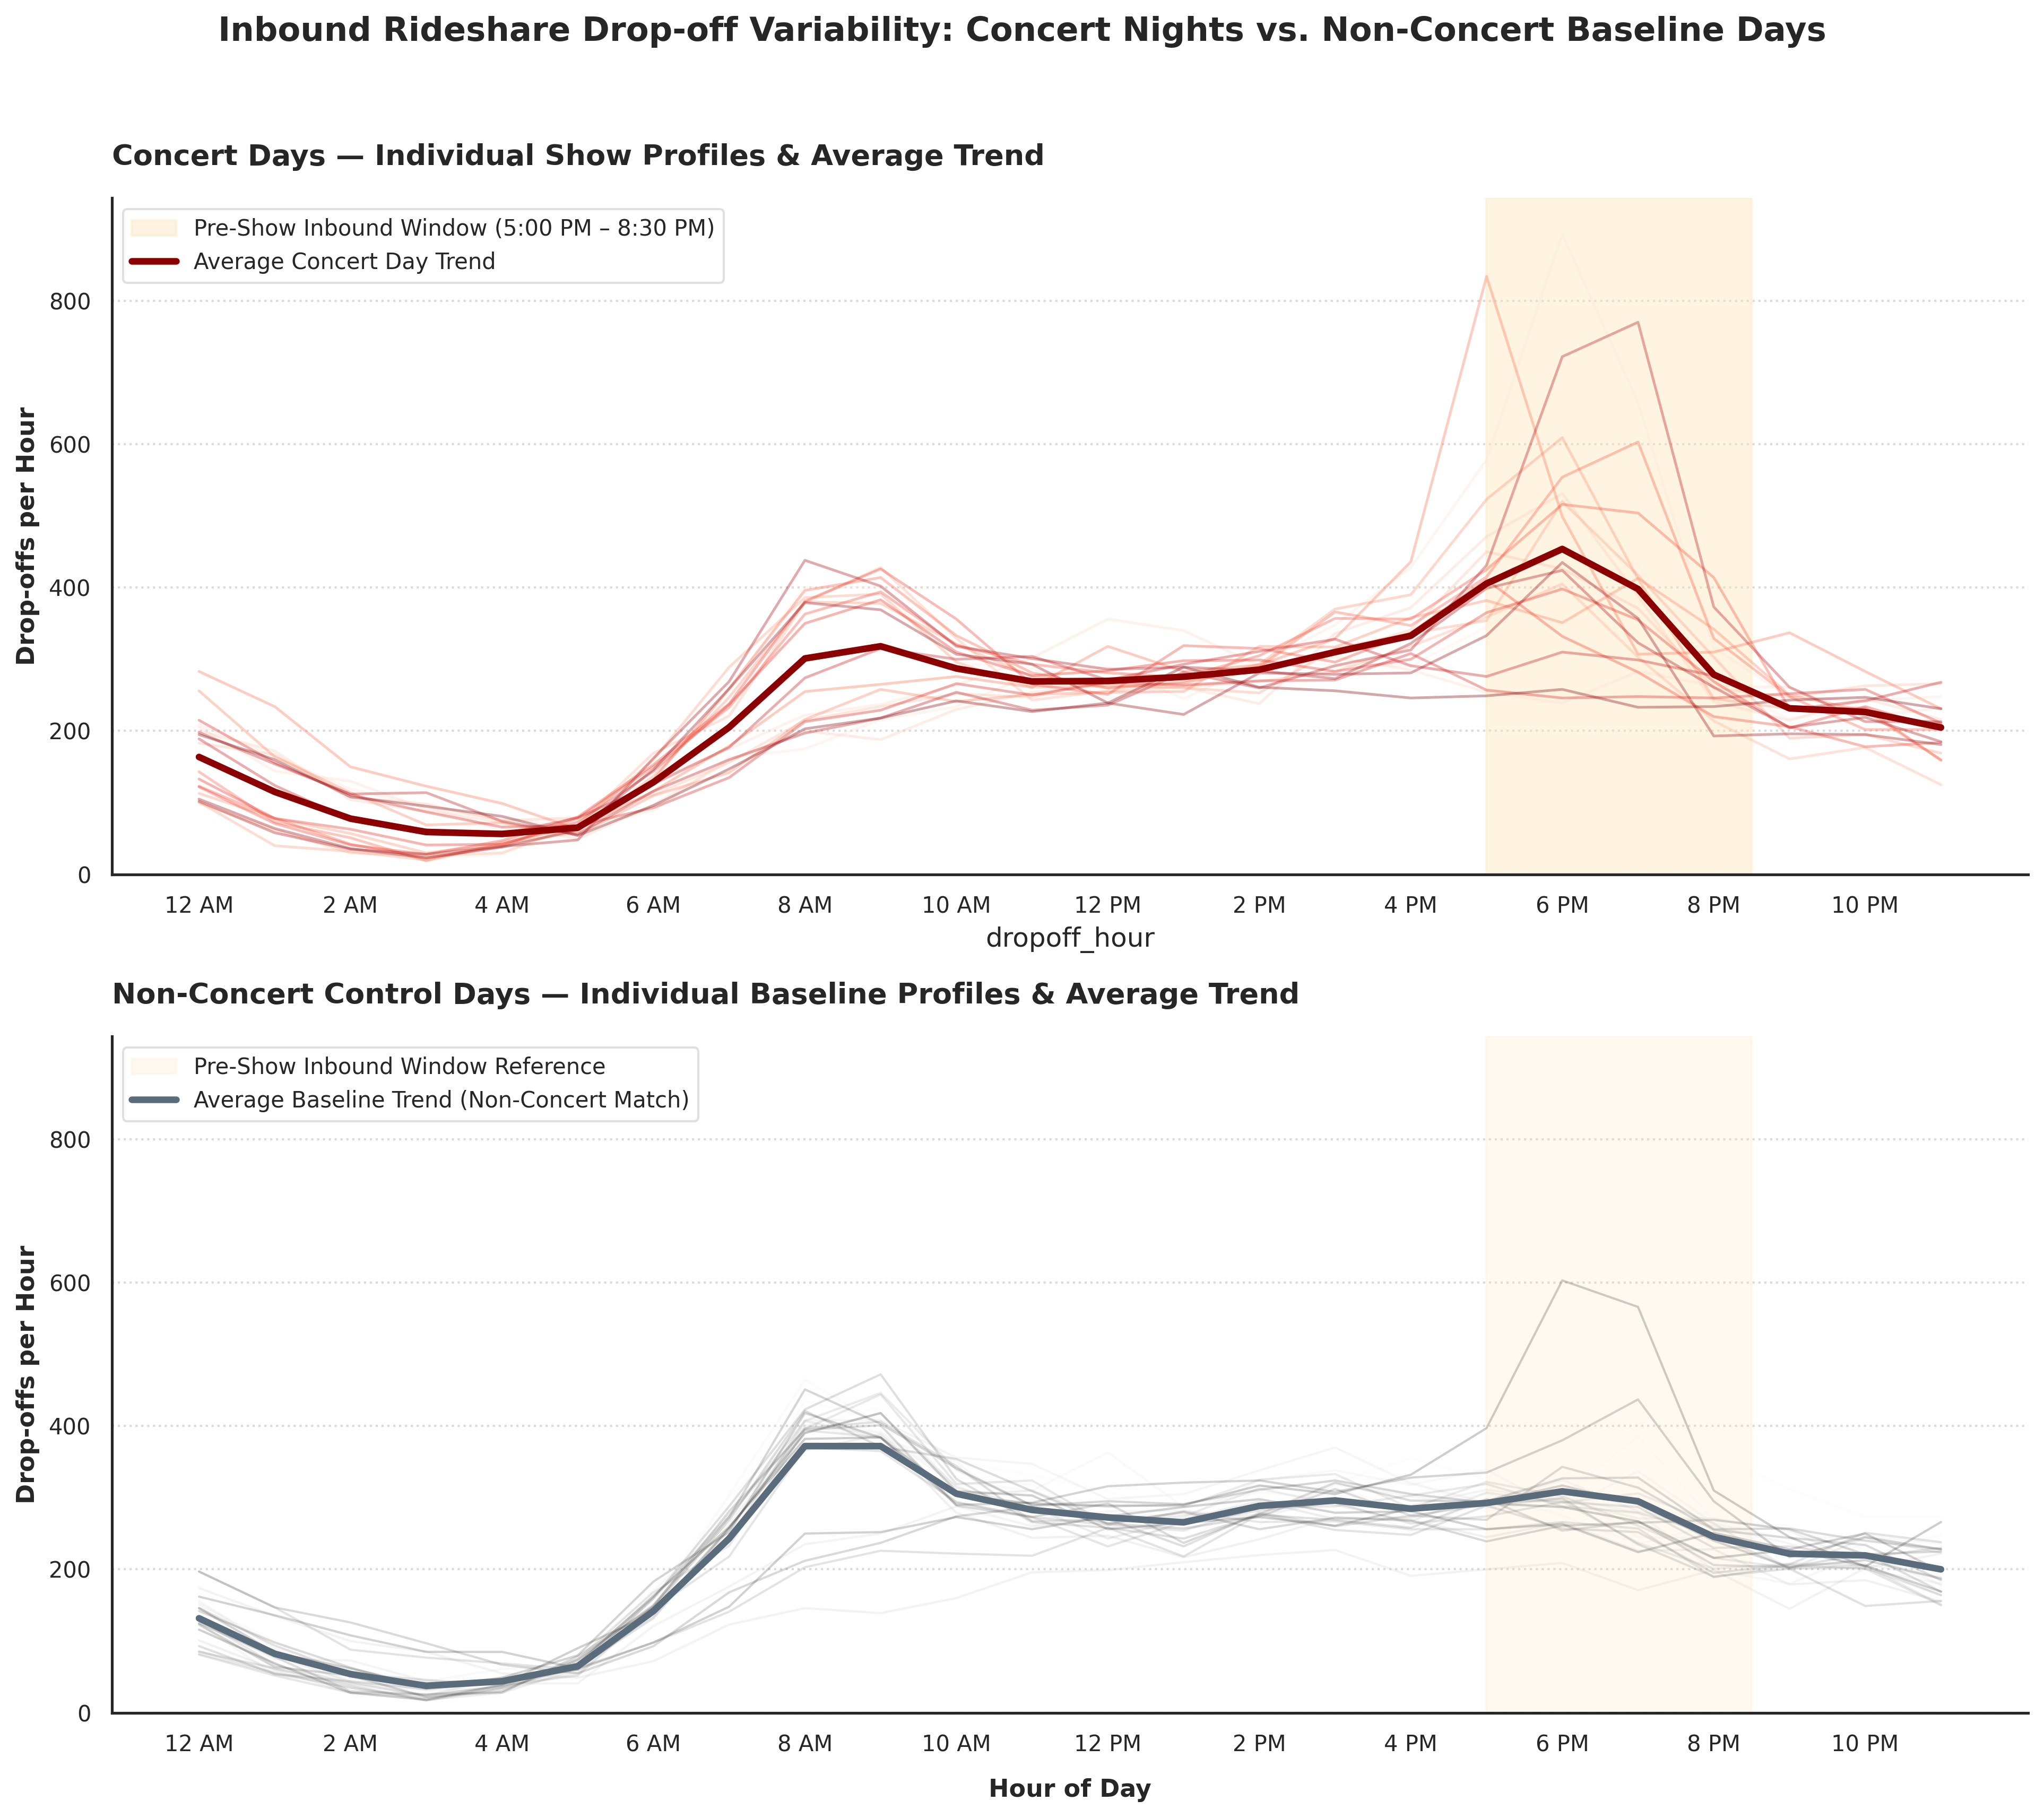

In [10]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. CONFIGURATION & PARAMETERS
# ==========================================
FFHV_FILES = {
    "June": "fhvhv_tripdata_2026-06.parquet",
    "July": "fhvhv_tripdata_2026-07.parquet",
    "August": "fhvhv_tripdata_2026-08.parquet"
}

# Official 2026 Concert Dates at Forest Hills Stadium for June, July & August
CONCERT_DATES = [
    # June 2026
    "2026-06-06", "2026-06-10", "2026-06-13", "2026-06-19",
    "2026-06-20", "2026-06-27",
    # July 2026
    "2026-07-08", "2026-07-09", "2026-07-11", "2026-07-17",
    "2026-07-18", "2026-07-21", "2026-07-23",
    # August 2026
    "2026-08-15", "2026-08-20", "2026-08-21", "2026-08-22",
    "2026-08-27", "2026-08-28", "2026-08-29"
]
concert_set = set(CONCERT_DATES)
VENUE_ZONE_ID = 95  # Forest Hills Zone

concert_rows = []
control_rows = []

# ==========================================
# 2. DATA EXTRACTION & SEPARATION
# ==========================================
for month, file_path in FHV_FILES.items():
    if not os.path.exists(file_path):
        print(f"Warning: {file_path} not found. Skipping {month}...")
        continue

    df = pd.read_parquet(file_path, columns=['dropoff_datetime', 'DOLocationID'])
    df = df[df['DOLocationID'] == VENUE_ZONE_ID].copy()

    dropoff_dt = pd.to_datetime(df['dropoff_datetime'])
    df['dropoff_date_str'] = dropoff_dt.dt.date.astype(str)
    df['dropoff_hour'] = dropoff_dt.dt.hour
    df['dropoff_dow'] = dropoff_dt.dt.dayofweek

    is_concert = df['dropoff_date_str'].isin(concert_set)
    concert_dow = df[is_concert]['dropoff_dow'].unique()
    control_mask = (~is_concert) & (df['dropoff_dow'].isin(concert_dow))

    concert_rows.append(df[is_concert][['dropoff_date_str', 'dropoff_hour']])
    control_rows.append(df[control_mask][['dropoff_date_str', 'dropoff_hour']])

c_df = pd.concat(concert_rows, ignore_index=True)
ctl_df = pd.concat(control_rows, ignore_index=True)

# --- Concert Data Aggregation & Reindexing ---
c_counts = c_df.groupby(['dropoff_date_str', 'dropoff_hour']).size().reset_index(name='trips')
c_full_idx = pd.MultiIndex.from_product([list(concert_set), range(24)], names=['dropoff_date_str', 'dropoff_hour'])
c_counts = c_counts.set_index(['dropoff_date_str', 'dropoff_hour']).reindex(c_full_idx, fill_value=0).reset_index()
c_mean = c_counts.groupby('dropoff_hour')['trips'].mean().reset_index()

# --- Control Data Aggregation & Reindexing ---
unique_control_dates = ctl_df['dropoff_date_str'].unique()
ctl_counts = ctl_df.groupby(['dropoff_date_str', 'dropoff_hour']).size().reset_index(name='trips')
ctl_full_idx = pd.MultiIndex.from_product([list(unique_control_dates), range(24)], names=['dropoff_date_str', 'dropoff_hour'])
ctl_counts = ctl_counts.set_index(['dropoff_date_str', 'dropoff_hour']).reindex(ctl_full_idx, fill_value=0).reset_index()
ctl_mean = ctl_counts.groupby('dropoff_hour')['trips'].mean().reset_index()

# ==========================================
# 3. TWO-PANEL SPAGHETTI PLOT
# ==========================================
fig, axes = plt.subplots(2, 1, figsize=(13, 12), dpi=300, sharey=True)
sns.set_theme(style="white")

# Determine shared Y-axis limit for accurate visual comparison
max_y = max(c_counts['trips'].max(), ctl_counts['trips'].max()) + 50

# --- Top Panel: Concert Days ---
axes[0].axvspan(17, 20.5, color='#FFE5B4', alpha=0.4, label='Pre-Show Inbound Window (5:00 PM – 8:30 PM)')
sns.lineplot(
    data=c_counts, x='dropoff_hour', y='trips', hue='dropoff_date_str',
    units='dropoff_date_str', estimator=None, palette='Reds', alpha=0.35, linewidth=1.2, legend=False, ax=axes[0]
)
sns.lineplot(
    data=c_mean, x='dropoff_hour', y='trips', color='#8B0000', linewidth=3, label='Average Concert Day Trend', ax=axes[0]
)
axes[0].set_title("Concert Days — Individual Show Profiles & Average Trend", fontsize=13, fontweight='bold', pad=15, loc='left')
axes[0].set_ylabel("Drop-offs per Hour", fontsize=11, fontweight='semibold')
axes[0].set_ylim(0, max_y)
axes[0].grid(axis='y', linestyle=':', alpha=0.7, color='#CCCCCC')
axes[0].legend(frameon=True, facecolor='white', edgecolor='#DDDDDD', fontsize=10, loc='upper left', framealpha=0.9)

# --- Bottom Panel: Non-Concert Control Days ---
axes[1].axvspan(17, 20.5, color='#FFE5B4', alpha=0.2, label='Pre-Show Inbound Window Reference')
sns.lineplot(
    data=ctl_counts, x='dropoff_hour', y='trips', hue='dropoff_date_str',
    units='dropoff_date_str', estimator=None, palette='Greys', alpha=0.2, linewidth=1.0, legend=False, ax=axes[1]
)
sns.lineplot(
    data=ctl_mean, x='dropoff_hour', y='trips', color='#5A6B7C', linewidth=3, label='Average Baseline Trend (Non-Concert Match)', ax=axes[1]
)
axes[1].set_title("Non-Concert Control Days — Individual Baseline Profiles & Average Trend", fontsize=13, fontweight='bold', pad=15, loc='left')
axes[1].set_xlabel("Hour of Day", fontsize=11, fontweight='semibold', labelpad=10)
axes[1].set_ylabel("Drop-offs per Hour", fontsize=11, fontweight='semibold')
axes[1].set_ylim(0, max_y)
axes[1].grid(axis='y', linestyle=':', alpha=0.7, color='#CCCCCC')
axes[1].legend(frameon=True, facecolor='white', edgecolor='#DDDDDD', fontsize=10, loc='upper left', framealpha=0.9)

# --- Common Formatting ---
hour_labels = ['12 AM', '2 AM', '4 AM', '6 AM', '8 AM', '10 AM', '12 PM',
               '2 PM', '4 PM', '6 PM', '8 PM', '10 PM']
for ax in axes:
    ax.set_xticks(range(0, 24, 2))
    ax.set_xticklabels(hour_labels, fontsize=10)
    ax.tick_params(axis='y', labelsize=10)
    sns.despine(ax=ax, top=True, right=True)

plt.suptitle("Inbound Rideshare Drop-off Variability: Concert Nights vs. Non-Concert Baseline Days", fontsize=15, fontweight='bold', y=0.95)
plt.tight_layout(rect=[0, 0, 1, 0.93])

plt.show()

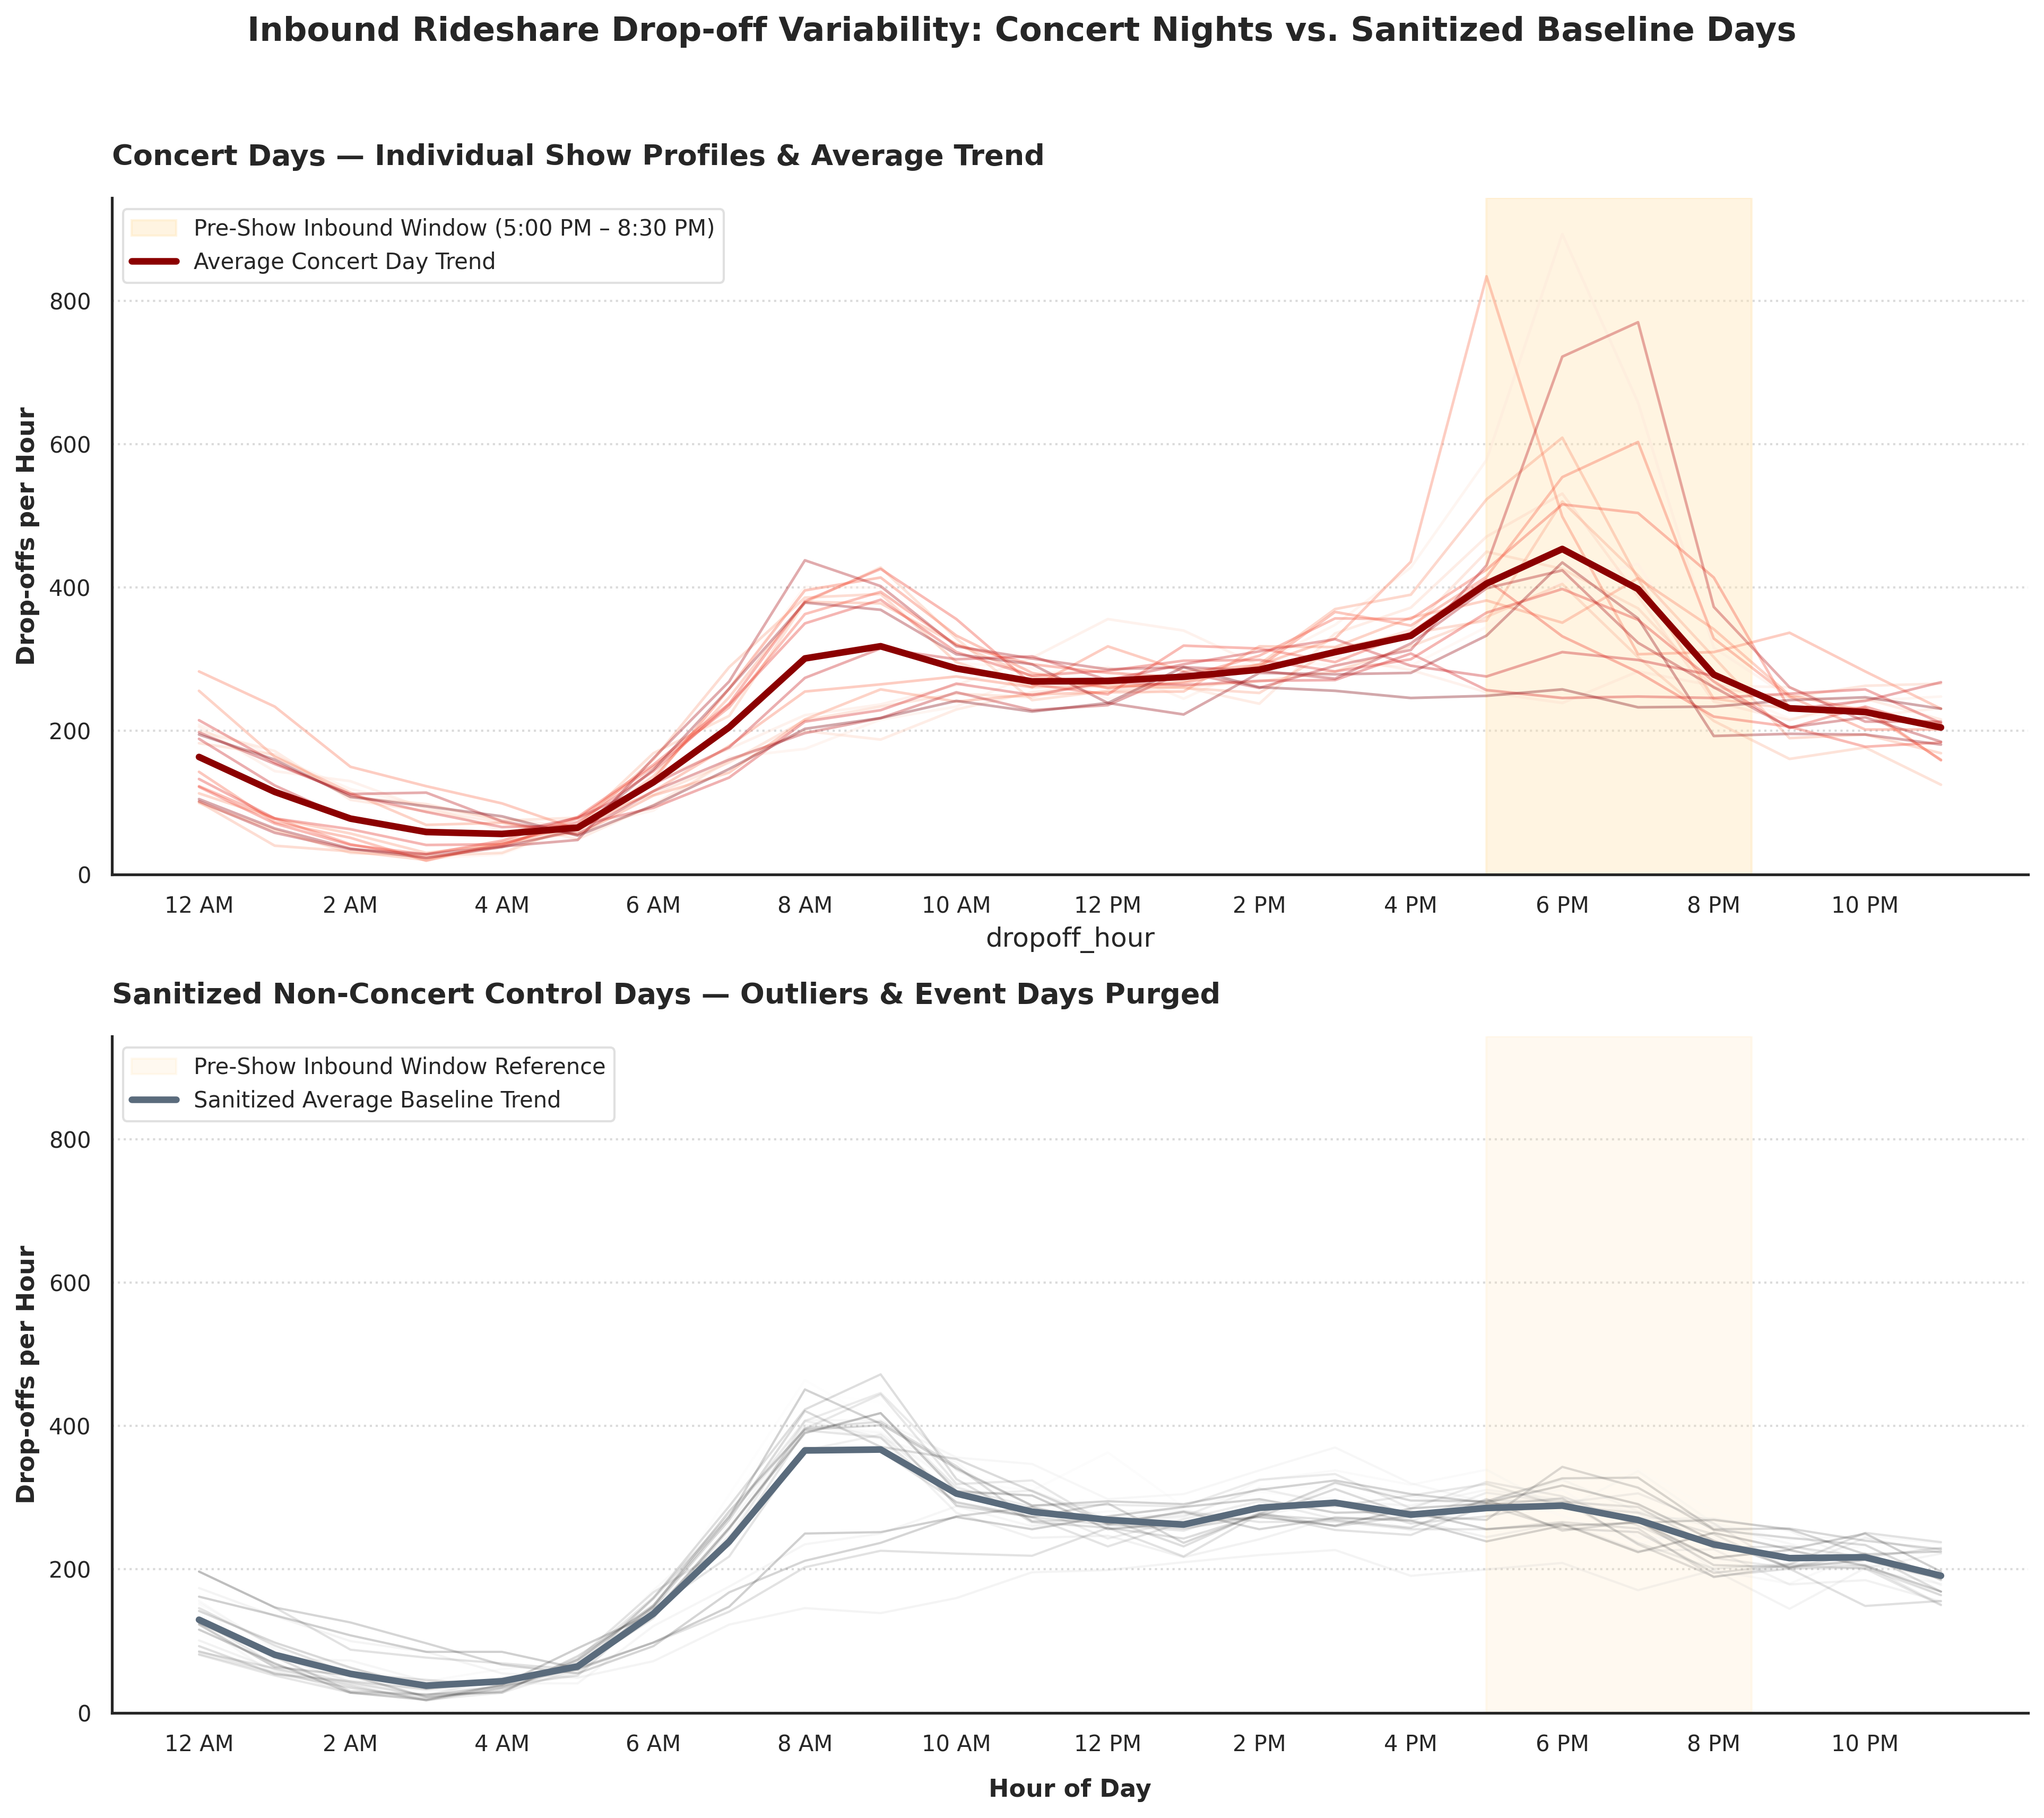

In [11]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. CONFIGURATION & PARAMETERS
# ==========================================
FFHV_FILES = {
    "June": "fhvhv_tripdata_2026-06.parquet",
    "July": "fhvhv_tripdata_2026-07.parquet",
    "August": "fhvhv_tripdata_2026-08.parquet"
}

# Official 2026 Concert Dates at Forest Hills Stadium for June, July & August
CONCERT_DATES = [
    # June 2026
    "2026-06-06", "2026-06-10", "2026-06-13", "2026-06-19",
    "2026-06-20", "2026-06-27",
    # July 2026
    "2026-07-08", "2026-07-09", "2026-07-11", "2026-07-17",
    "2026-07-18", "2026-07-21", "2026-07-23",
    # August 2026
    "2026-08-15", "2026-08-20", "2026-08-21", "2026-08-22",
    "2026-08-27", "2026-08-28", "2026-08-29"
]
concert_set = set(CONCERT_DATES)
VENUE_ZONE_ID = 95  # Forest Hills Zone

concert_rows = []
control_rows = []

# ==========================================
# 2. DATA EXTRACTION & INITIAL SEPARATION
# ==========================================
for month, file_path in FHV_FILES.items():
    if not os.path.exists(file_path):
        print(f"Warning: {file_path} not found. Skipping {month}...")
        continue

    df = pd.read_parquet(file_path, columns=['dropoff_datetime', 'DOLocationID'])
    df = df[df['DOLocationID'] == VENUE_ZONE_ID].copy()

    dropoff_dt = pd.to_datetime(df['dropoff_datetime'])
    df['dropoff_date_str'] = dropoff_dt.dt.date.astype(str)
    df['dropoff_hour'] = dropoff_dt.dt.hour
    df['dropoff_dow'] = dropoff_dt.dt.dayofweek

    is_concert = df['dropoff_date_str'].isin(concert_set)
    concert_dow = df[is_concert]['dropoff_dow'].unique()
    control_mask = (~is_concert) & (df['dropoff_dow'].isin(concert_dow))

    concert_rows.append(df[is_concert][['dropoff_date_str', 'dropoff_hour']])
    control_rows.append(df[control_mask][['dropoff_date_str', 'dropoff_hour']])

c_df = pd.concat(concert_rows, ignore_index=True)
ctl_raw_df = pd.concat(control_rows, ignore_index=True)

# ==========================================
# 3. CORRECTED BASELINE SANITIZATION (ANOMALY FILTER)
# ==========================================
# Calculate peak hourly drop-offs between 5 PM and 8 PM for each candidate control date
evening_hourly = ctl_raw_df[ctl_raw_df['dropoff_hour'].between(17, 20)].groupby(['dropoff_date_str', 'dropoff_hour']).size().reset_index(name='hourly_trips')
evening_max = evening_hourly.groupby('dropoff_date_str')['hourly_trips'].max().reset_index(name='max_evening_peak')

# Retain control dates where the evening peak does not exceed 380 drop-offs/hr (filtering out hidden events)
valid_control_dates = evening_max[evening_max['max_evening_peak'] <= 380]['dropoff_date_str'].tolist()

# Filter control dataset
ctl_df = ctl_raw_df[ctl_raw_df['dropoff_date_str'].isin(valid_control_dates)].copy()

# --- Concert Data Aggregation & Reindexing ---
c_counts = c_df.groupby(['dropoff_date_str', 'dropoff_hour']).size().reset_index(name='trips')
c_full_idx = pd.MultiIndex.from_product([list(concert_set), range(24)], names=['dropoff_date_str', 'dropoff_hour'])
c_counts = c_counts.set_index(['dropoff_date_str', 'dropoff_hour']).reindex(c_full_idx, fill_value=0).reset_index()
c_mean = c_counts.groupby('dropoff_hour')['trips'].mean().reset_index()

# --- Control Data Aggregation & Reindexing ---
ctl_counts = ctl_df.groupby(['dropoff_date_str', 'dropoff_hour']).size().reset_index(name='trips')
ctl_full_idx = pd.MultiIndex.from_product([valid_control_dates, range(24)], names=['dropoff_date_str', 'dropoff_hour'])
ctl_counts = ctl_counts.set_index(['dropoff_date_str', 'dropoff_hour']).reindex(ctl_full_idx, fill_value=0).reset_index()
ctl_mean = ctl_counts.groupby('dropoff_hour')['trips'].mean().reset_index()

# ==========================================
# 4. TWO-PANEL SANITIZED SPAGHETTI PLOT
# ==========================================
fig, axes = plt.subplots(2, 1, figsize=(13, 12), dpi=300, sharey=True)
sns.set_theme(style="white")

max_y = max(c_counts['trips'].max(), ctl_counts['trips'].max()) + 50

# --- Top Panel: Concert Days ---
axes[0].axvspan(17, 20.5, color='#FFE5B4', alpha=0.4, label='Pre-Show Inbound Window (5:00 PM – 8:30 PM)')
sns.lineplot(
    data=c_counts, x='dropoff_hour', y='trips', hue='dropoff_date_str',
    units='dropoff_date_str', estimator=None, palette='Reds', alpha=0.35, linewidth=1.2, legend=False, ax=axes[0]
)
sns.lineplot(
    data=c_mean, x='dropoff_hour', y='trips', color='#8B0000', linewidth=3, label='Average Concert Day Trend', ax=axes[0]
)
axes[0].set_title("Concert Days — Individual Show Profiles & Average Trend", fontsize=13, fontweight='bold', pad=15, loc='left')
axes[0].set_ylabel("Drop-offs per Hour", fontsize=11, fontweight='semibold')
axes[0].set_ylim(0, max_y)
axes[0].grid(axis='y', linestyle=':', alpha=0.7, color='#CCCCCC')
axes[0].legend(frameon=True, facecolor='white', edgecolor='#DDDDDD', fontsize=10, loc='upper left', framealpha=0.9)

# --- Bottom Panel: Sanitized Non-Concert Control Days ---
axes[1].axvspan(17, 20.5, color='#FFE5B4', alpha=0.2, label='Pre-Show Inbound Window Reference')
sns.lineplot(
    data=ctl_counts, x='dropoff_hour', y='trips', hue='dropoff_date_str',
    units='dropoff_date_str', estimator=None, palette='Greys', alpha=0.2, linewidth=1.0, legend=False, ax=axes[1]
)
sns.lineplot(
    data=ctl_mean, x='dropoff_hour', y='trips', color='#5A6B7C', linewidth=3, label='Sanitized Average Baseline Trend', ax=axes[1]
)
axes[1].set_title("Sanitized Non-Concert Control Days — Outliers & Event Days Purged", fontsize=13, fontweight='bold', pad=15, loc='left')
axes[1].set_xlabel("Hour of Day", fontsize=11, fontweight='semibold', labelpad=10)
axes[1].set_ylabel("Drop-offs per Hour", fontsize=11, fontweight='semibold')
axes[1].set_ylim(0, max_y)
axes[1].grid(axis='y', linestyle=':', alpha=0.7, color='#CCCCCC')
axes[1].legend(frameon=True, facecolor='white', edgecolor='#DDDDDD', fontsize=10, loc='upper left', framealpha=0.9)

# --- Common Formatting ---
hour_labels = ['12 AM', '2 AM', '4 AM', '6 AM', '8 AM', '10 AM', '12 PM',
               '2 PM', '4 PM', '6 PM', '8 PM', '10 PM']
for ax in axes:
    ax.set_xticks(range(0, 24, 2))
    ax.set_xticklabels(hour_labels, fontsize=10)
    ax.tick_params(axis='y', labelsize=10)
    sns.despine(ax=ax, top=True, right=True)

plt.suptitle("Inbound Rideshare Drop-off Variability: Concert Nights vs. Sanitized Baseline Days", fontsize=15, fontweight='bold', y=0.95)
plt.tight_layout(rect=[0, 0, 1, 0.93])

plt.show()

Fetching 311 service requests from NYC Open Data API for ZIP 11375...


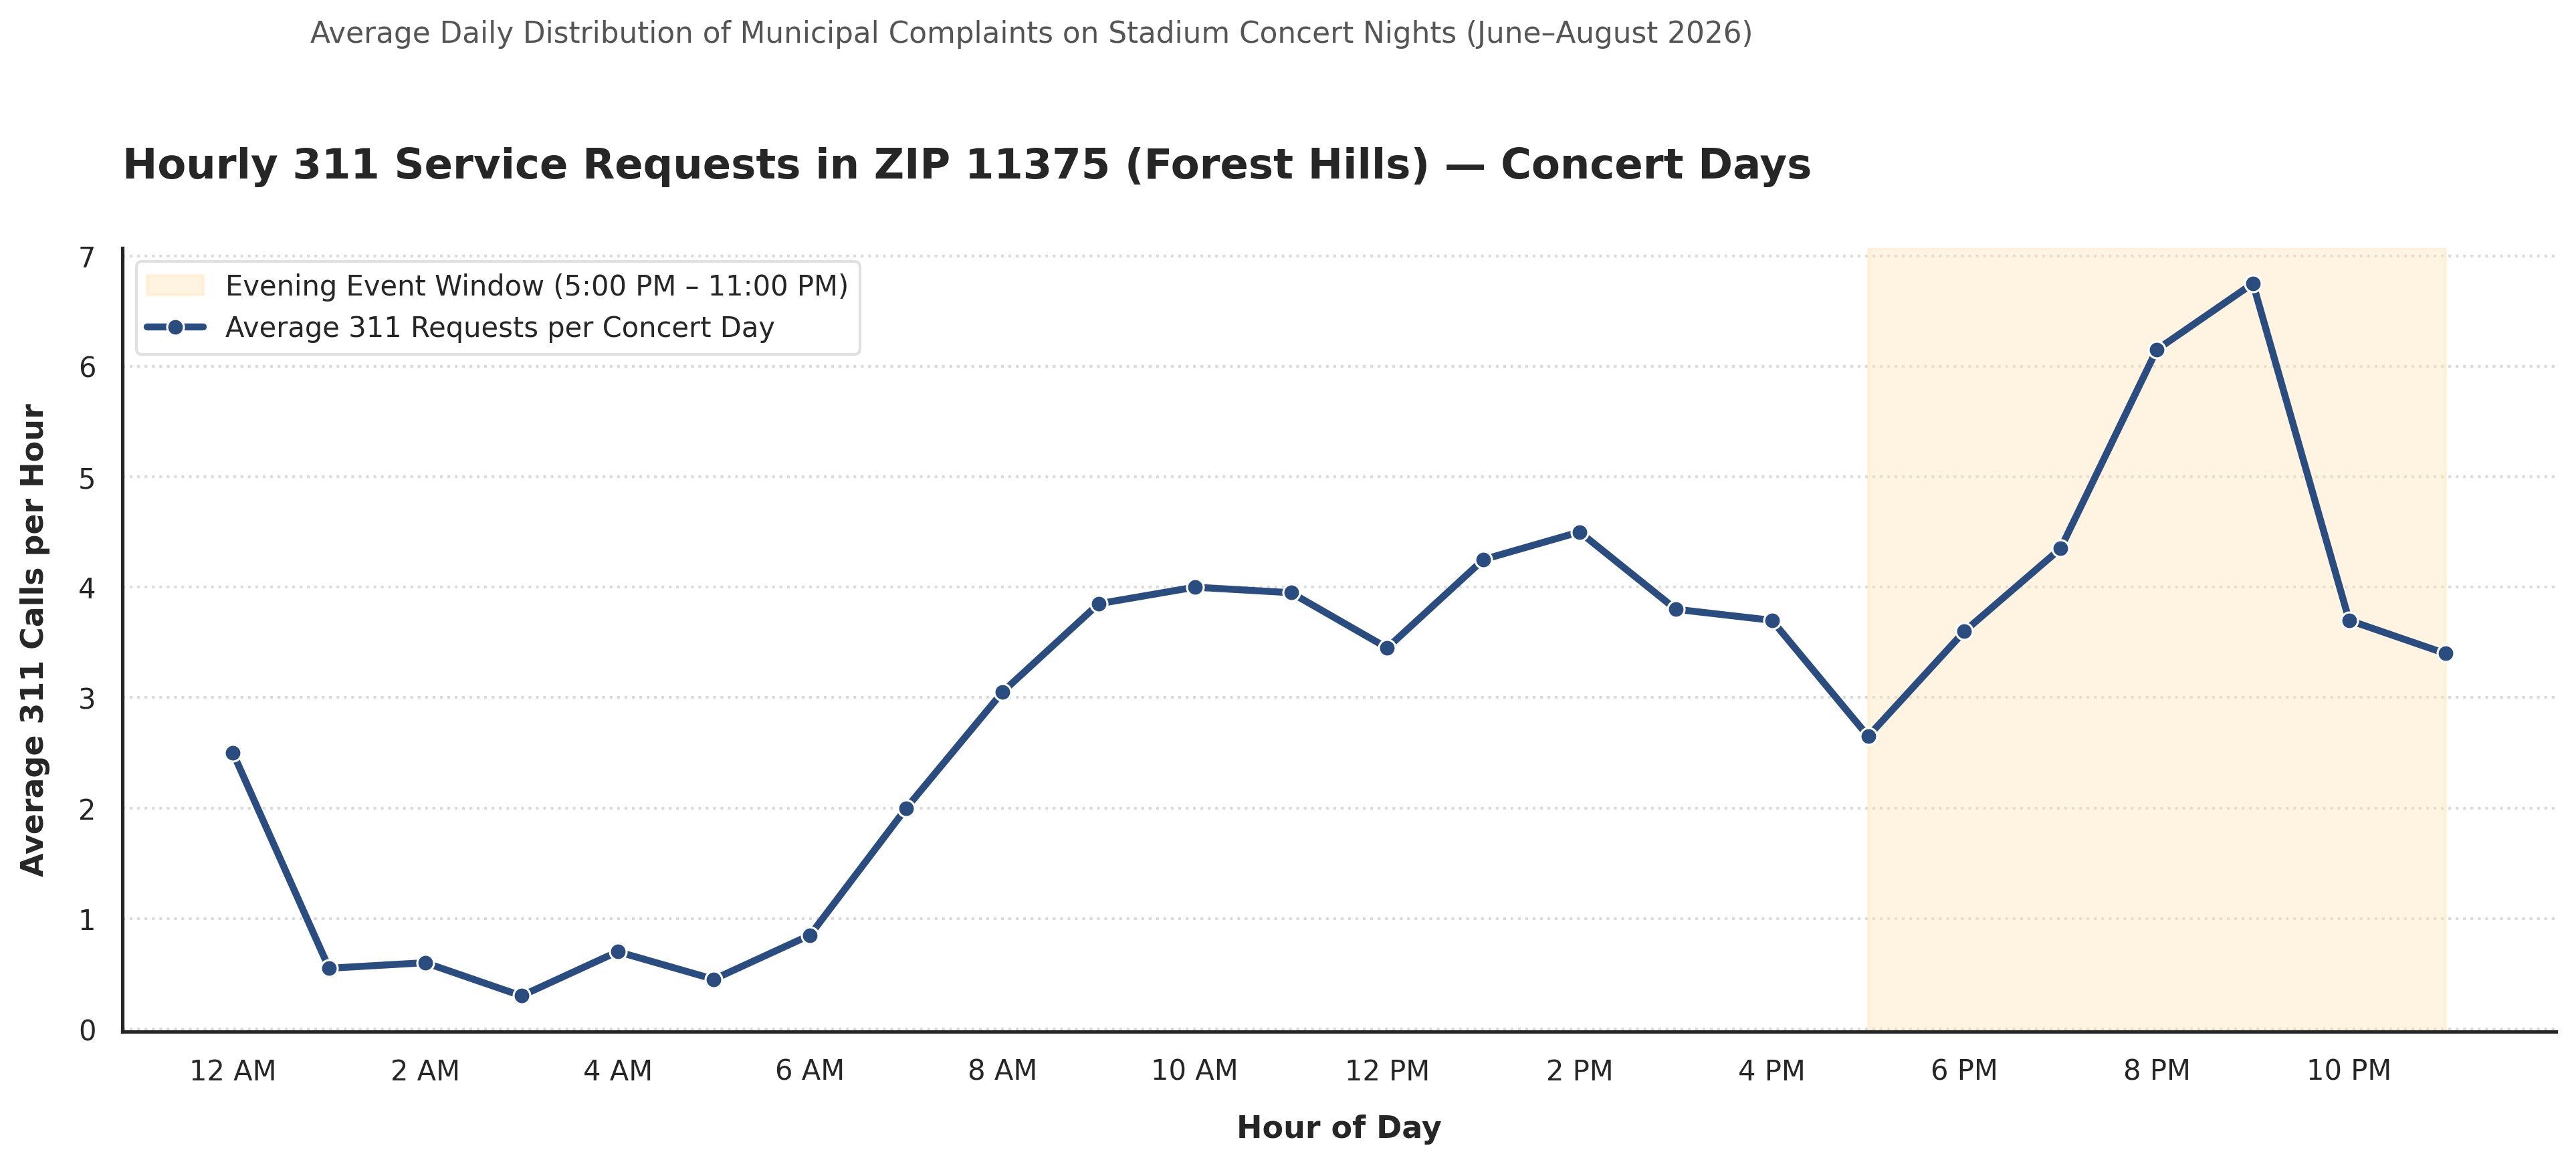

In [13]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. FETCH 311 DATA FROM NYC OPEN DATA API
# ==========================================
url = "https://data.cityofnewyork.us/resource/erm2-nwe9.json"

# Query for zip code 11375 across June - August 2026
where_clause = "incident_zip='11375' AND created_date >= '2026-06-01T00:00:00' AND created_date <= '2026-08-31T23:59:59'"
params = {
    "$where": where_clause,
    "$limit": 50000,
    "$select": "unique_key, created_date, incident_zip, complaint_type"
}

print("Fetching 311 service requests from NYC Open Data API for ZIP 11375...")
response = requests.get(url, params=params)
data = response.json()

if not data:
    print("No data returned or check API limits/filters.")
else:
    df_311 = pd.DataFrame(data)

    # Process timestamps and extract date and hour
    created_dt = pd.to_datetime(df_311['created_date'])
    df_311['date_str'] = created_dt.dt.date.astype(str)
    df_311['hour'] = created_dt.dt.hour

    # Official 2026 Concert Dates for Forest Hills Stadium
    CONCERT_DATES = [
        # June 2026
        "2026-06-06", "2026-06-10", "2026-06-13", "2026-06-19",
        "2026-06-20", "2026-06-27",
        # July 2026
        "2026-07-08", "2026-07-09", "2026-07-11", "2026-07-17",
        "2026-07-18", "2026-07-21", "2026-07-23",
        # August 2026
        "2026-08-15", "2026-08-20", "2026-08-21", "2026-08-22",
        "2026-08-27", "2026-08-28", "2026-08-29"
    ]
    concert_set = set(CONCERT_DATES)

    # Filter for concert days only
    concert_311 = df_311[df_311['date_str'].isin(concert_set)].copy()

    # Aggregate average 311 calls per hour per concert day
    num_concert_days = len(concert_set)
    hourly_counts = concert_311.groupby('hour').size().reset_index(name='total_calls')
    hourly_counts['avg_calls'] = hourly_counts['total_calls'] / num_concert_days

    # Ensure all 24 hours are represented
    full_hours = pd.DataFrame({'hour': range(24)})
    plot_df = full_hours.merge(hourly_counts, on='hour', how='left').fillna(0)

    # ==========================================
    # 2. PROFESSIONAL HOURLY PLOTTING
    # ==========================================
    plt.figure(figsize=(13, 6.5), dpi=300)
    sns.set_theme(style="white")

    # Highlight evening event window (5 PM - 11 PM)
    plt.axvspan(17, 23, color='#FFE5B4', alpha=0.4, label='Evening Event Window (5:00 PM – 11:00 PM)')

    sns.lineplot(
        data=plot_df, x='hour', y='avg_calls',
        color='#2B4C7E', linewidth=2.5, marker='o', markersize=6,
        label='Average 311 Requests per Concert Day'
    )

    plt.title("Hourly 311 Service Requests in ZIP 11375 (Forest Hills) — Concert Days", fontsize=15, fontweight='bold', pad=25, loc='left')
    plt.suptitle("Average Daily Distribution of Municipal Complaints on Stadium Concert Nights (June–August 2026)", fontsize=10.5, color='#555555', x=0.125, y=0.92, ha='left')

    plt.xlabel("Hour of Day", fontsize=11, fontweight='semibold', labelpad=10)
    plt.ylabel("Average 311 Calls per Hour", fontsize=11, fontweight='semibold', labelpad=10)

    hour_labels = ['12 AM', '2 AM', '4 AM', '6 AM', '8 AM', '10 AM', '12 PM',
                   '2 PM', '4 PM', '6 PM', '8 PM', '10 PM']
    plt.xticks(range(0, 24, 2), hour_labels, fontsize=10)
    plt.yticks(fontsize=10)

    plt.grid(axis='y', linestyle=':', alpha=0.7, color='#CCCCCC')
    sns.despine(top=True, right=True)

    plt.legend(frameon=True, facecolor='white', edgecolor='#DDDDDD', fontsize=10, loc='upper left', framealpha=0.9)
    plt.tight_layout(rect=[0, 0.03, 1, 0.90])

    plt.show()

Fetching 311 service requests from NYC Open Data API for ZIP 11375...


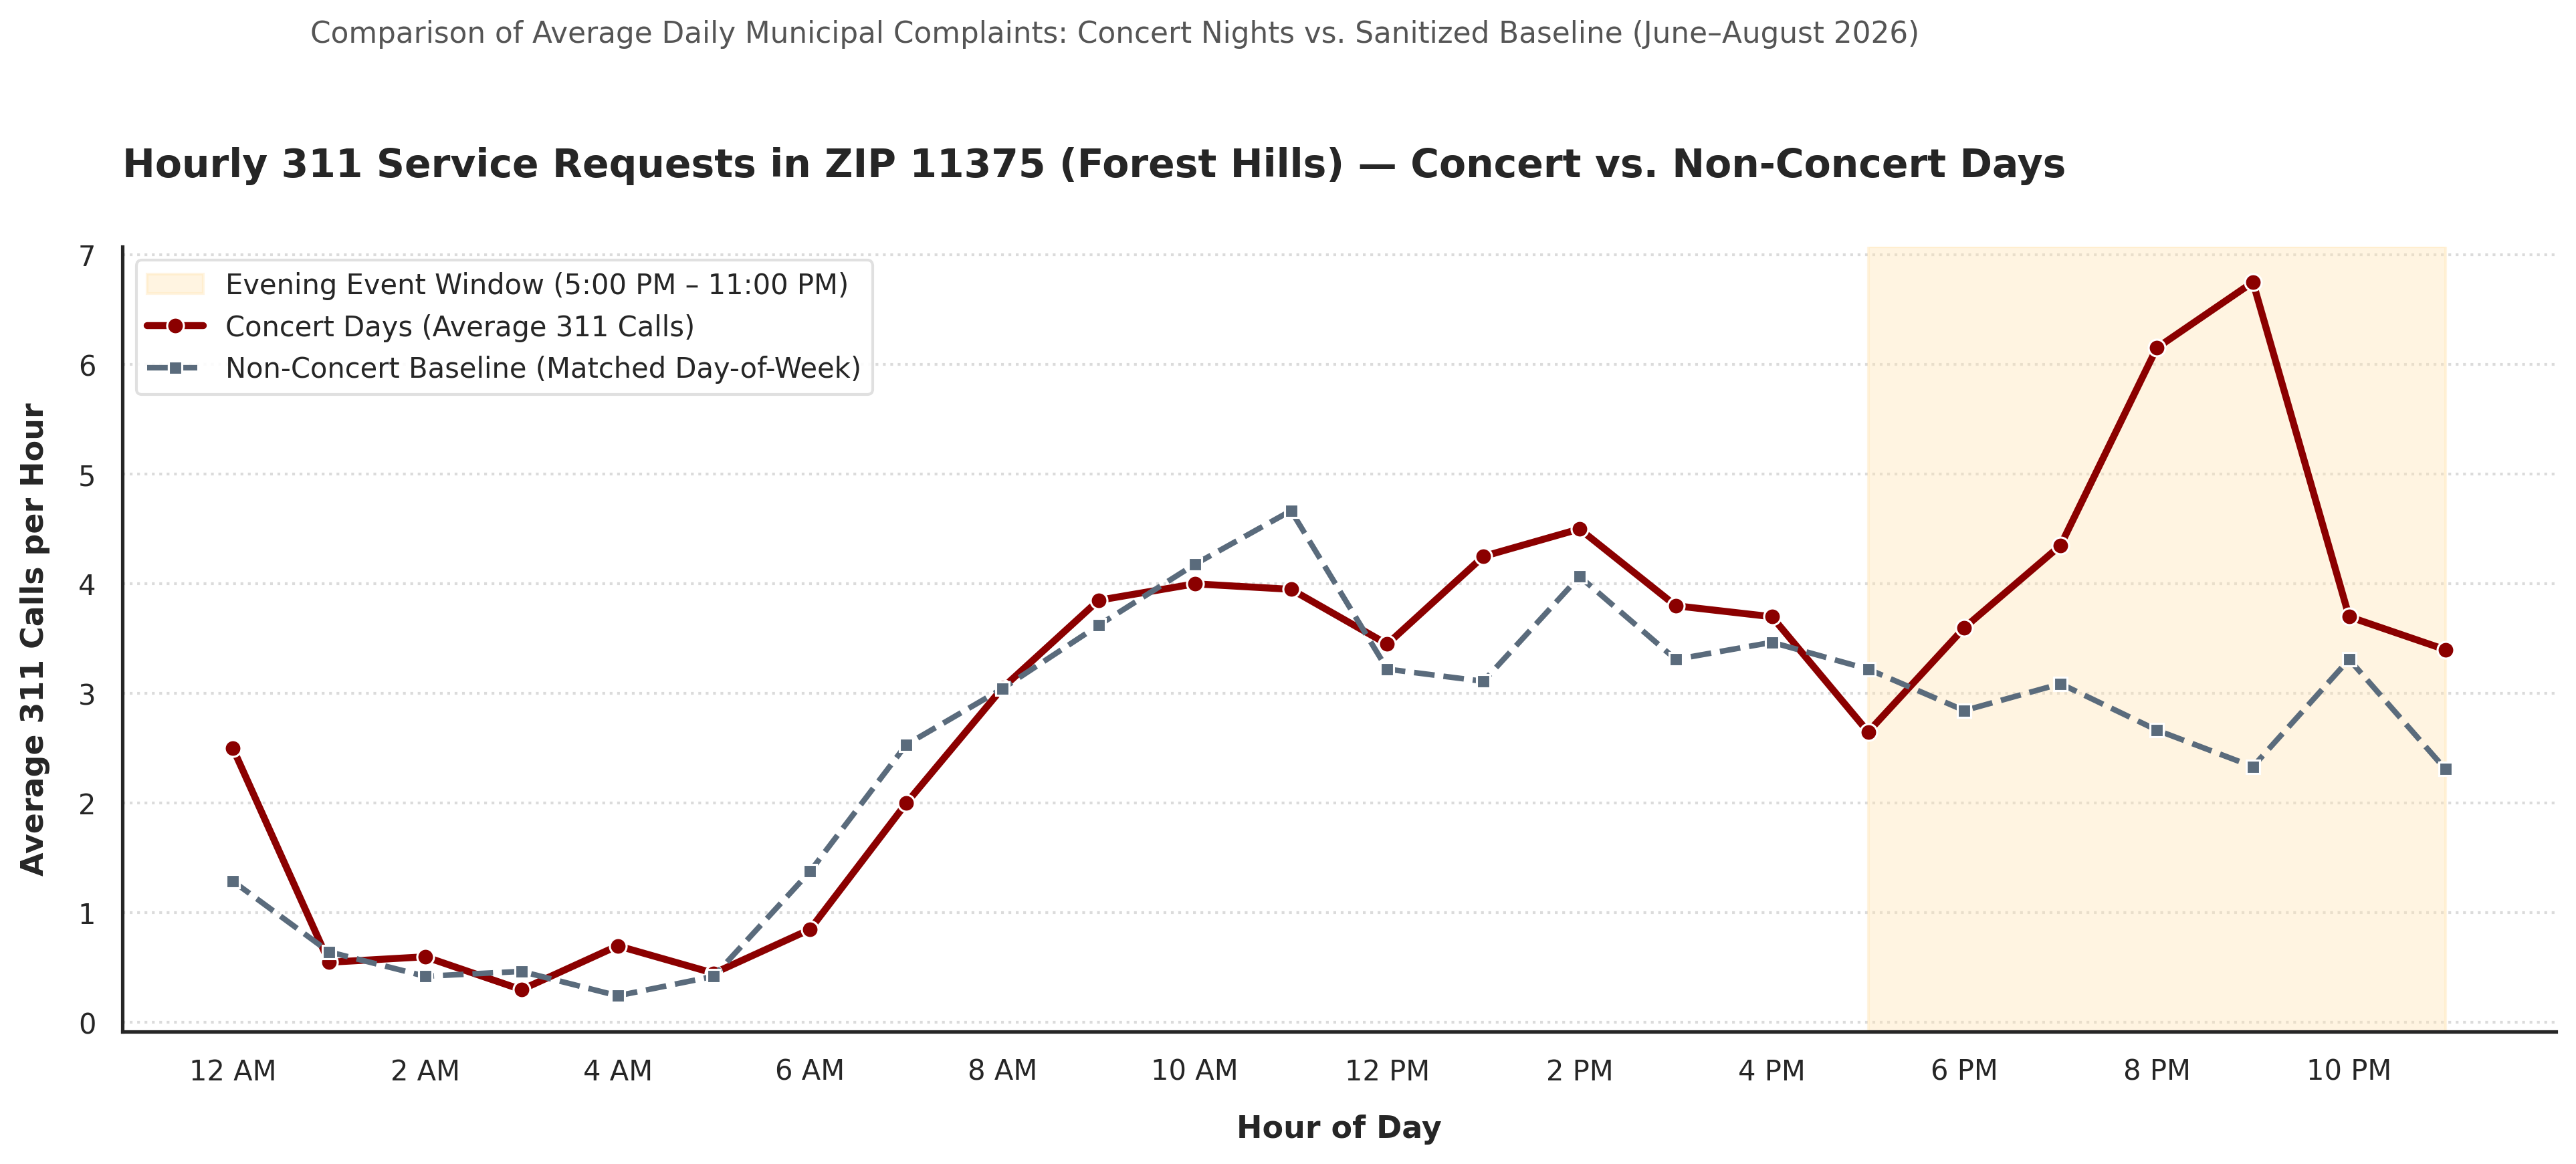

In [14]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. FETCH 311 DATA FROM NYC OPEN DATA API
# ==========================================
url = "https://data.cityofnewyork.us/resource/erm2-nwe9.json"
where_clause = "incident_zip='11375' AND created_date >= '2026-06-01T00:00:00' AND created_date <= '2026-08-31T23:59:59'"
params = {
    "$where": where_clause,
    "$limit": 50000,
    "$select": "unique_key, created_date, incident_zip, complaint_type"
}

print("Fetching 311 service requests from NYC Open Data API for ZIP 11375...")
response = requests.get(url, params=params)
data = response.json()

if not data:
    print("No data returned or check API limits/filters.")
else:
    df_311 = pd.DataFrame(data)

    created_dt = pd.to_datetime(df_311['created_date'])
    df_311['date_str'] = created_dt.dt.date.astype(str)
    df_311['hour'] = created_dt.dt.hour
    df_311['day_of_week'] = created_dt.dt.dayofweek

    # Official 2026 Concert Dates for Forest Hills Stadium
    CONCERT_DATES = [
        # June 2026
        "2026-06-06", "2026-06-10", "2026-06-13", "2026-06-19",
        "2026-06-20", "2026-06-27",
        # July 2026
        "2026-07-08", "2026-07-09", "2026-07-11", "2026-07-17",
        "2026-07-18", "2026-07-21", "2026-07-23",
        # August 2026
        "2026-08-15", "2026-08-20", "2026-08-21", "2026-08-22",
        "2026-08-27", "2026-08-28", "2026-08-29"
    ]
    concert_set = set(CONCERT_DATES)

    # Separate concert vs control (matching day-of-week profile)
    is_concert = df_311['date_str'].isin(concert_set)
    concert_dow = df_311[is_concert]['day_of_week'].unique()
    control_mask = (~is_concert) & (df_311['day_of_week'].isin(concert_dow))

    concert_df = df_311[is_concert]
    control_df = df_311[control_mask]

    num_concert_days = len(concert_set)
    num_control_days = control_df['date_str'].nunique() if not control_df.empty else 1

    # Aggregate hourly averages normalized by day counts
    c_counts = concert_df.groupby('hour').size().reset_index(name='total_calls')
    c_counts['avg_calls'] = c_counts['total_calls'] / num_concert_days

    ctl_counts = control_df.groupby('hour').size().reset_index(name='total_calls')
    ctl_counts['avg_calls'] = ctl_counts['total_calls'] / num_control_days

    full_hours = pd.DataFrame({'hour': range(24)})
    plot_df = full_hours.merge(c_counts[['hour', 'avg_calls']], on='hour', how='left') \
                        .merge(ctl_counts[['hour', 'avg_calls']], on='hour', suffixes=('_concert', '_baseline'), how='left').fillna(0)

    # ==========================================
    # 2. PLOTTING CONCERT VS NON-CONCERT 311 CALLS
    # ==========================================
    plt.figure(figsize=(13, 6.5), dpi=300)
    sns.set_theme(style="white")

    # Highlight evening event window (5 PM - 11 PM)
    plt.axvspan(17, 23, color='#FFE5B4', alpha=0.4, label='Evening Event Window (5:00 PM – 11:00 PM)')

    sns.lineplot(
        data=plot_df, x='hour', y='avg_calls_concert',
        color='#8B0000', linewidth=2.5, marker='o', markersize=6,
        label='Concert Days (Average 311 Calls)'
    )
    sns.lineplot(
        data=plot_df, x='hour', y='avg_calls_baseline',
        color='#5A6B7C', linewidth=2, linestyle='--', marker='s', markersize=5,
        label='Non-Concert Baseline (Matched Day-of-Week)'
    )

    plt.title("Hourly 311 Service Requests in ZIP 11375 (Forest Hills) — Concert vs. Non-Concert Days", fontsize=14, fontweight='bold', pad=25, loc='left')
    plt.suptitle("Comparison of Average Daily Municipal Complaints: Concert Nights vs. Sanitized Baseline (June–August 2026)", fontsize=10.5, color='#555555', x=0.125, y=0.92, ha='left')

    plt.xlabel("Hour of Day", fontsize=11, fontweight='semibold', labelpad=10)
    plt.ylabel("Average 311 Calls per Hour", fontsize=11, fontweight='semibold', labelpad=10)

    hour_labels = ['12 AM', '2 AM', '4 AM', '6 AM', '8 AM', '10 AM', '12 PM',
                   '2 PM', '4 PM', '6 PM', '8 PM', '10 PM']
    plt.xticks(range(0, 24, 2), hour_labels, fontsize=10)
    plt.yticks(fontsize=10)

    plt.grid(axis='y', linestyle=':', alpha=0.7, color='#CCCCCC')
    sns.despine(top=True, right=True)

    plt.legend(frameon=True, facecolor='white', edgecolor='#DDDDDD', fontsize=10, loc='upper left', framealpha=0.9)
    plt.tight_layout(rect=[0, 0.03, 1, 0.90])

    plt.show()

Fetching 311 service requests from NYC Open Data API for ZIP 11375...


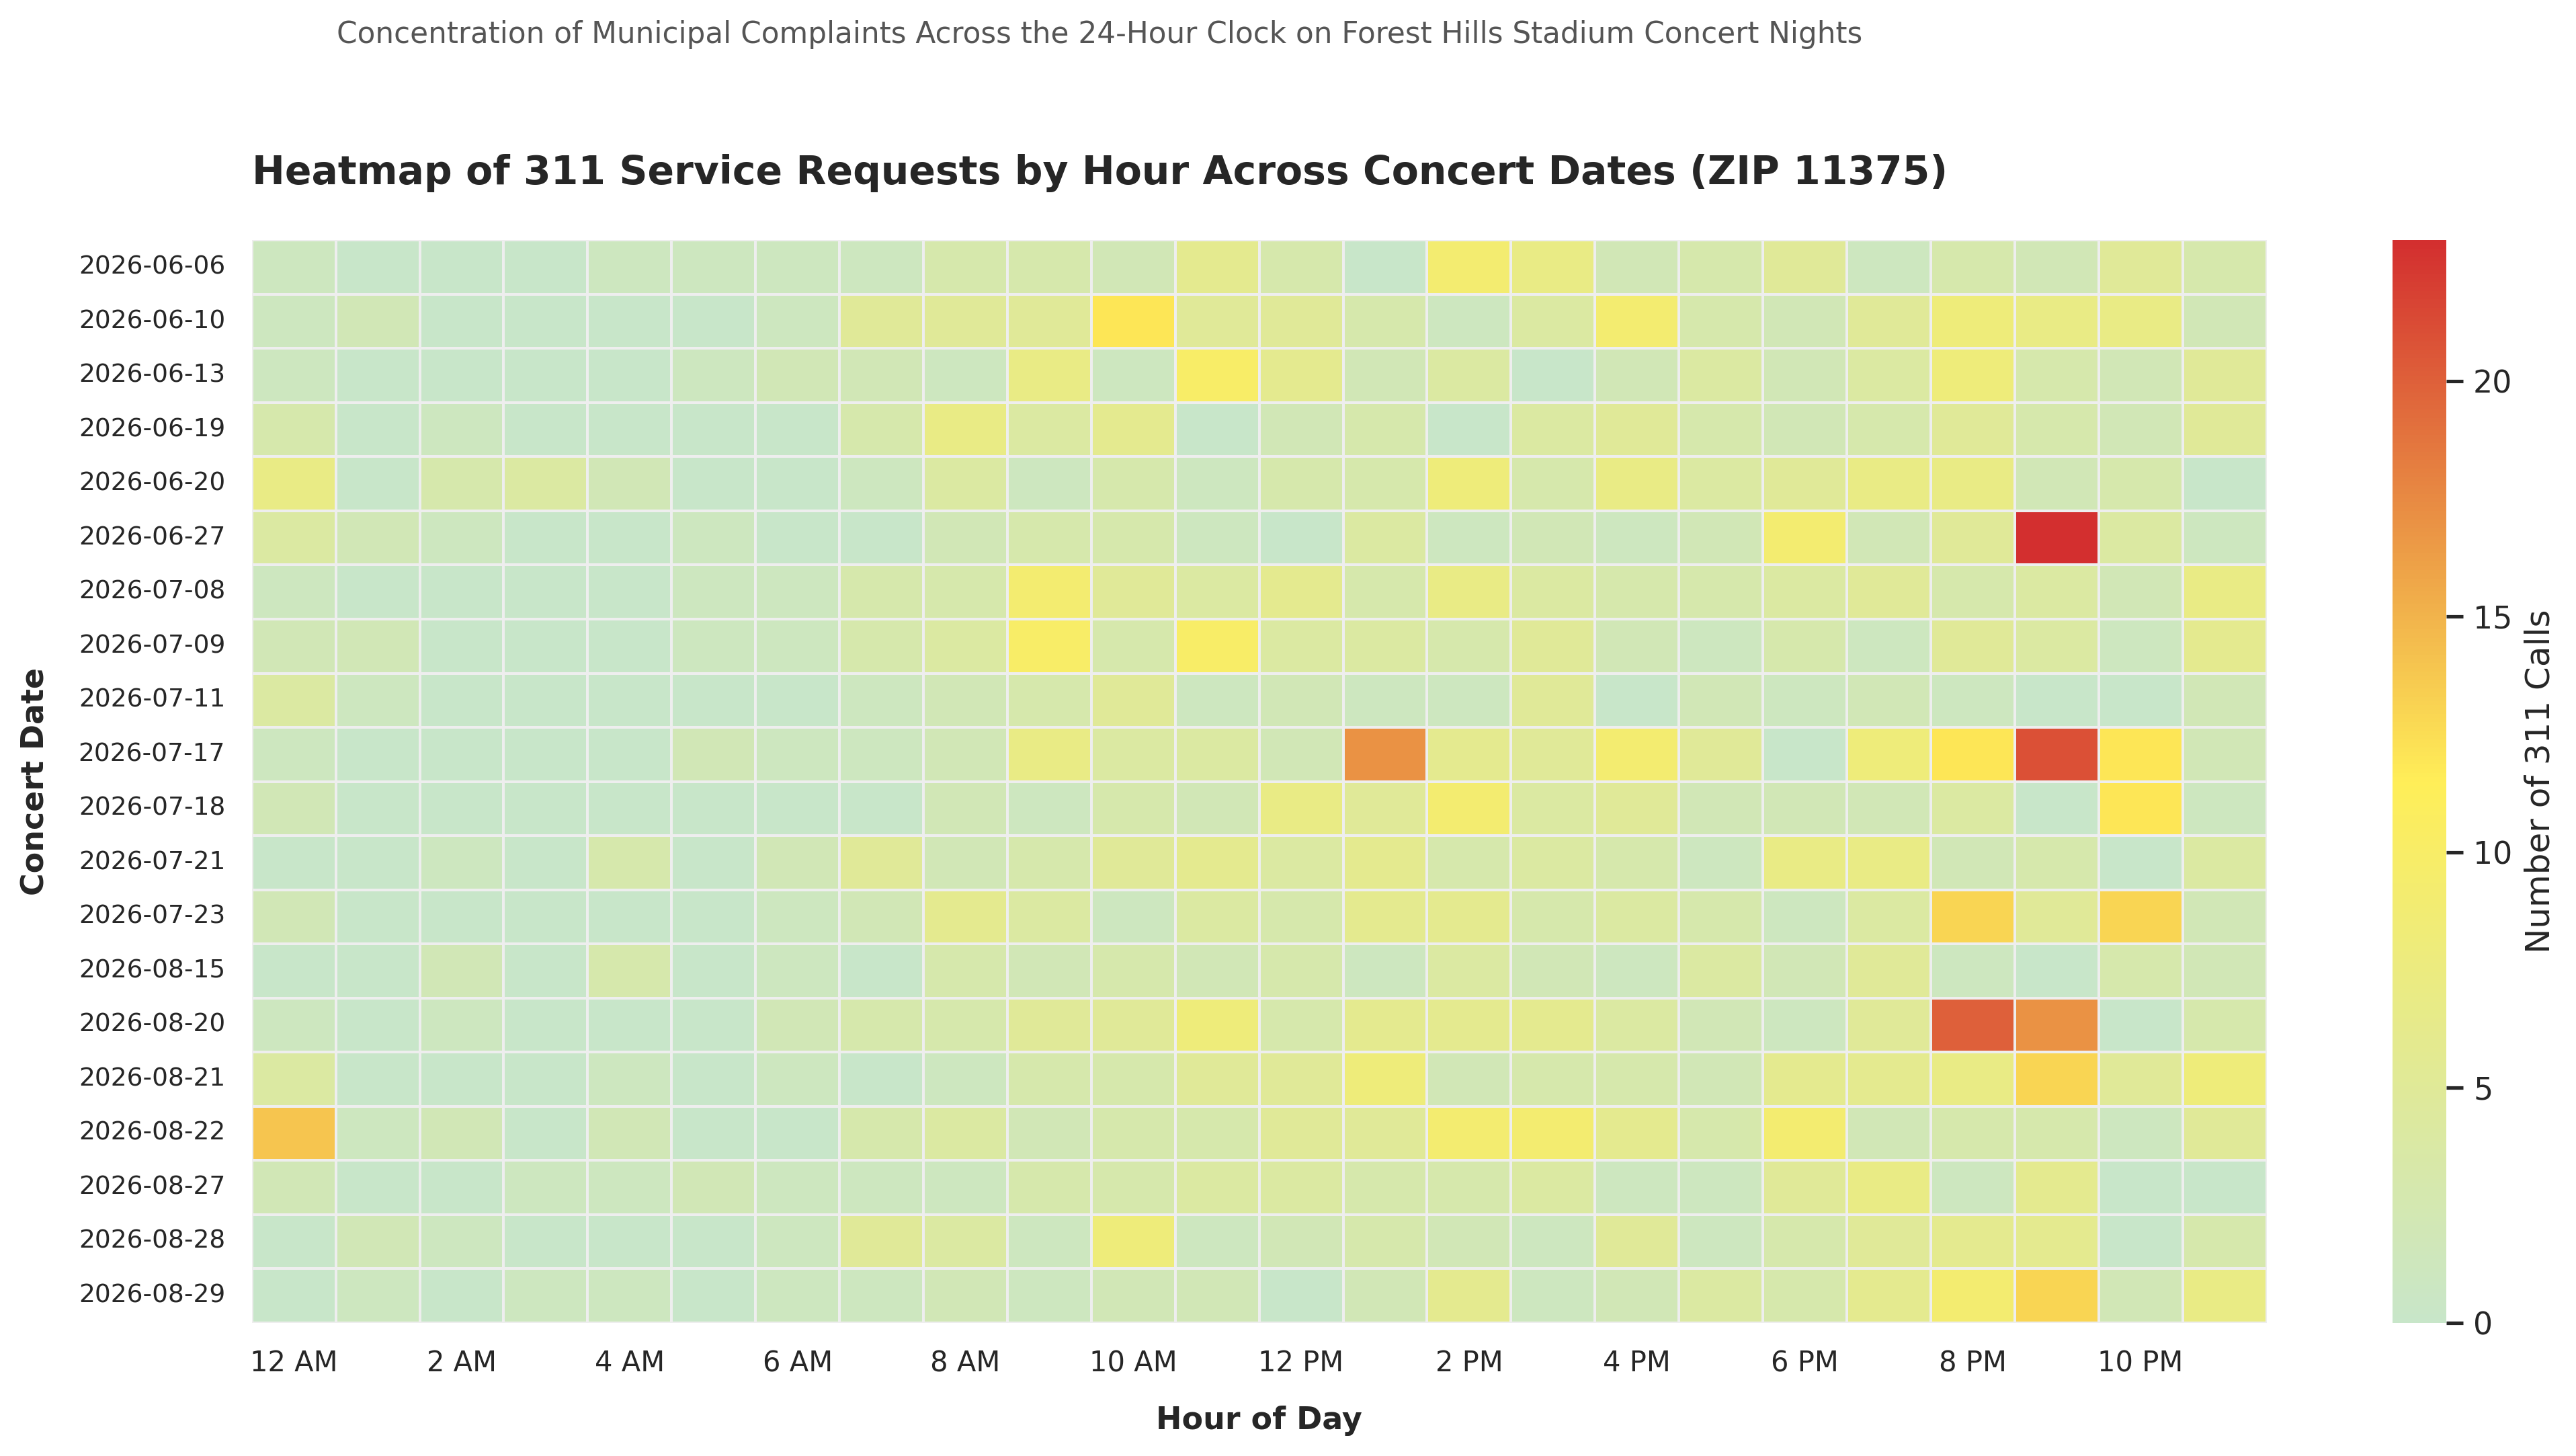

In [18]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# ==========================================
# 1. FETCH 311 DATA FROM NYC OPEN DATA API
# ==========================================
url = "https://data.cityofnewyork.us/resource/erm2-nwe9.json"
where_clause = "incident_zip='11375' AND created_date >= '2026-06-01T00:00:00' AND created_date <= '2026-08-31T23:59:59'"
params = {
    "$where": where_clause,
    "$limit": 50000,
    "$select": "unique_key, created_date, incident_zip, complaint_type"
}

print("Fetching 311 service requests from NYC Open Data API for ZIP 11375...")
response = requests.get(url, params=params)
data = response.json()

if not data:
    print("No data returned or check API limits/filters.")
else:
    df_311 = pd.DataFrame(data)

    created_dt = pd.to_datetime(df_311['created_date'])
    df_311['date_str'] = created_dt.dt.date.astype(str)
    df_311['hour'] = created_dt.dt.hour

    # Official 2026 Concert Dates for Forest Hills Stadium
    CONCERT_DATES = [
        # June 2026
        "2026-06-06", "2026-06-10", "2026-06-13", "2026-06-19",
        "2026-06-20", "2026-06-27",
        # July 2026
        "2026-07-08", "2026-07-09", "2026-07-11", "2026-07-17",
        "2026-07-18", "2026-07-21", "2026-07-23",
        # August 2026
        "2026-08-15", "2026-08-20", "2026-08-21", "2026-08-22",
        "2026-08-27", "2026-08-28", "2026-08-29"
    ]
    concert_set = set(CONCERT_DATES)

    # Filter for concert days only
    concert_311 = df_311[df_311['date_str'].isin(concert_set)].copy()

    # Aggregate counts by Date and Hour
    heatmap_data = concert_311.groupby(['date_str', 'hour']).size().reset_index(name='call_count')

    # Create pivot table: Rows = Concert Dates, Columns = Hours (0-23)
    pivot_df = heatmap_data.pivot(index='date_str', columns='hour', values='call_count').fillna(0)

    # Ensure all 24 hours (0-23) are present as columns
    for h in range(24):
        if h not in pivot_df.columns:
            pivot_df[h] = 0
    pivot_df = pivot_df[sorted(pivot_df.columns)]

    # Ensure all concert dates are present as rows
    all_concert_dates_sorted = sorted(list(concert_set))
    pivot_df = pivot_df.reindex(all_concert_dates_sorted, fill_value=0)

    # ==========================================
    # 2. PLOT HEATMAP (Light Green for Low)
    # ==========================================
    plt.figure(figsize=(14, 8), dpi=300)
    sns.set_theme(style="white")

    # Define custom colormap: Light Green -> Soft Yellow -> Dark Red
    custom_cmap = LinearSegmentedColormap.from_list(
        "lightgreen_yellow_red",
        ["#C8E6C9", "#FFEE58", "#D32F2F"]
    )

    ax = sns.heatmap(
        pivot_df,
        cmap=custom_cmap,
        linewidths=0.5,
        linecolor='#EEEEEE',
        cbar_kws={'label': 'Number of 311 Calls'}
    )

    plt.title("Heatmap of 311 Service Requests by Hour Across Concert Dates (ZIP 11375)", fontsize=14, fontweight='bold', pad=20, loc='left')
    plt.suptitle("Concentration of Municipal Complaints Across the 24-Hour Clock on Forest Hills Stadium Concert Nights", fontsize=10.5, color='#555555', x=0.125, y=0.93, ha='left')

    plt.xlabel("Hour of Day", fontsize=11, fontweight='semibold', labelpad=10)
    plt.ylabel("Concert Date", fontsize=11, fontweight='semibold', labelpad=10)

    hour_labels = ['12 AM', '2 AM', '4 AM', '6 AM', '8 AM', '10 AM', '12 PM',
                   '2 PM', '4 PM', '6 PM', '8 PM', '10 PM']
    plt.xticks(ticks=[i + 0.5 for i in range(0, 24, 2)], labels=hour_labels, rotation=0, fontsize=10)
    plt.yticks(fontsize=9, rotation=0)

    plt.tight_layout(rect=[0, 0.03, 1, 0.91])
    plt.show()

Fetching NYPD collision data from NYC Open Data API for ZIP 11375...


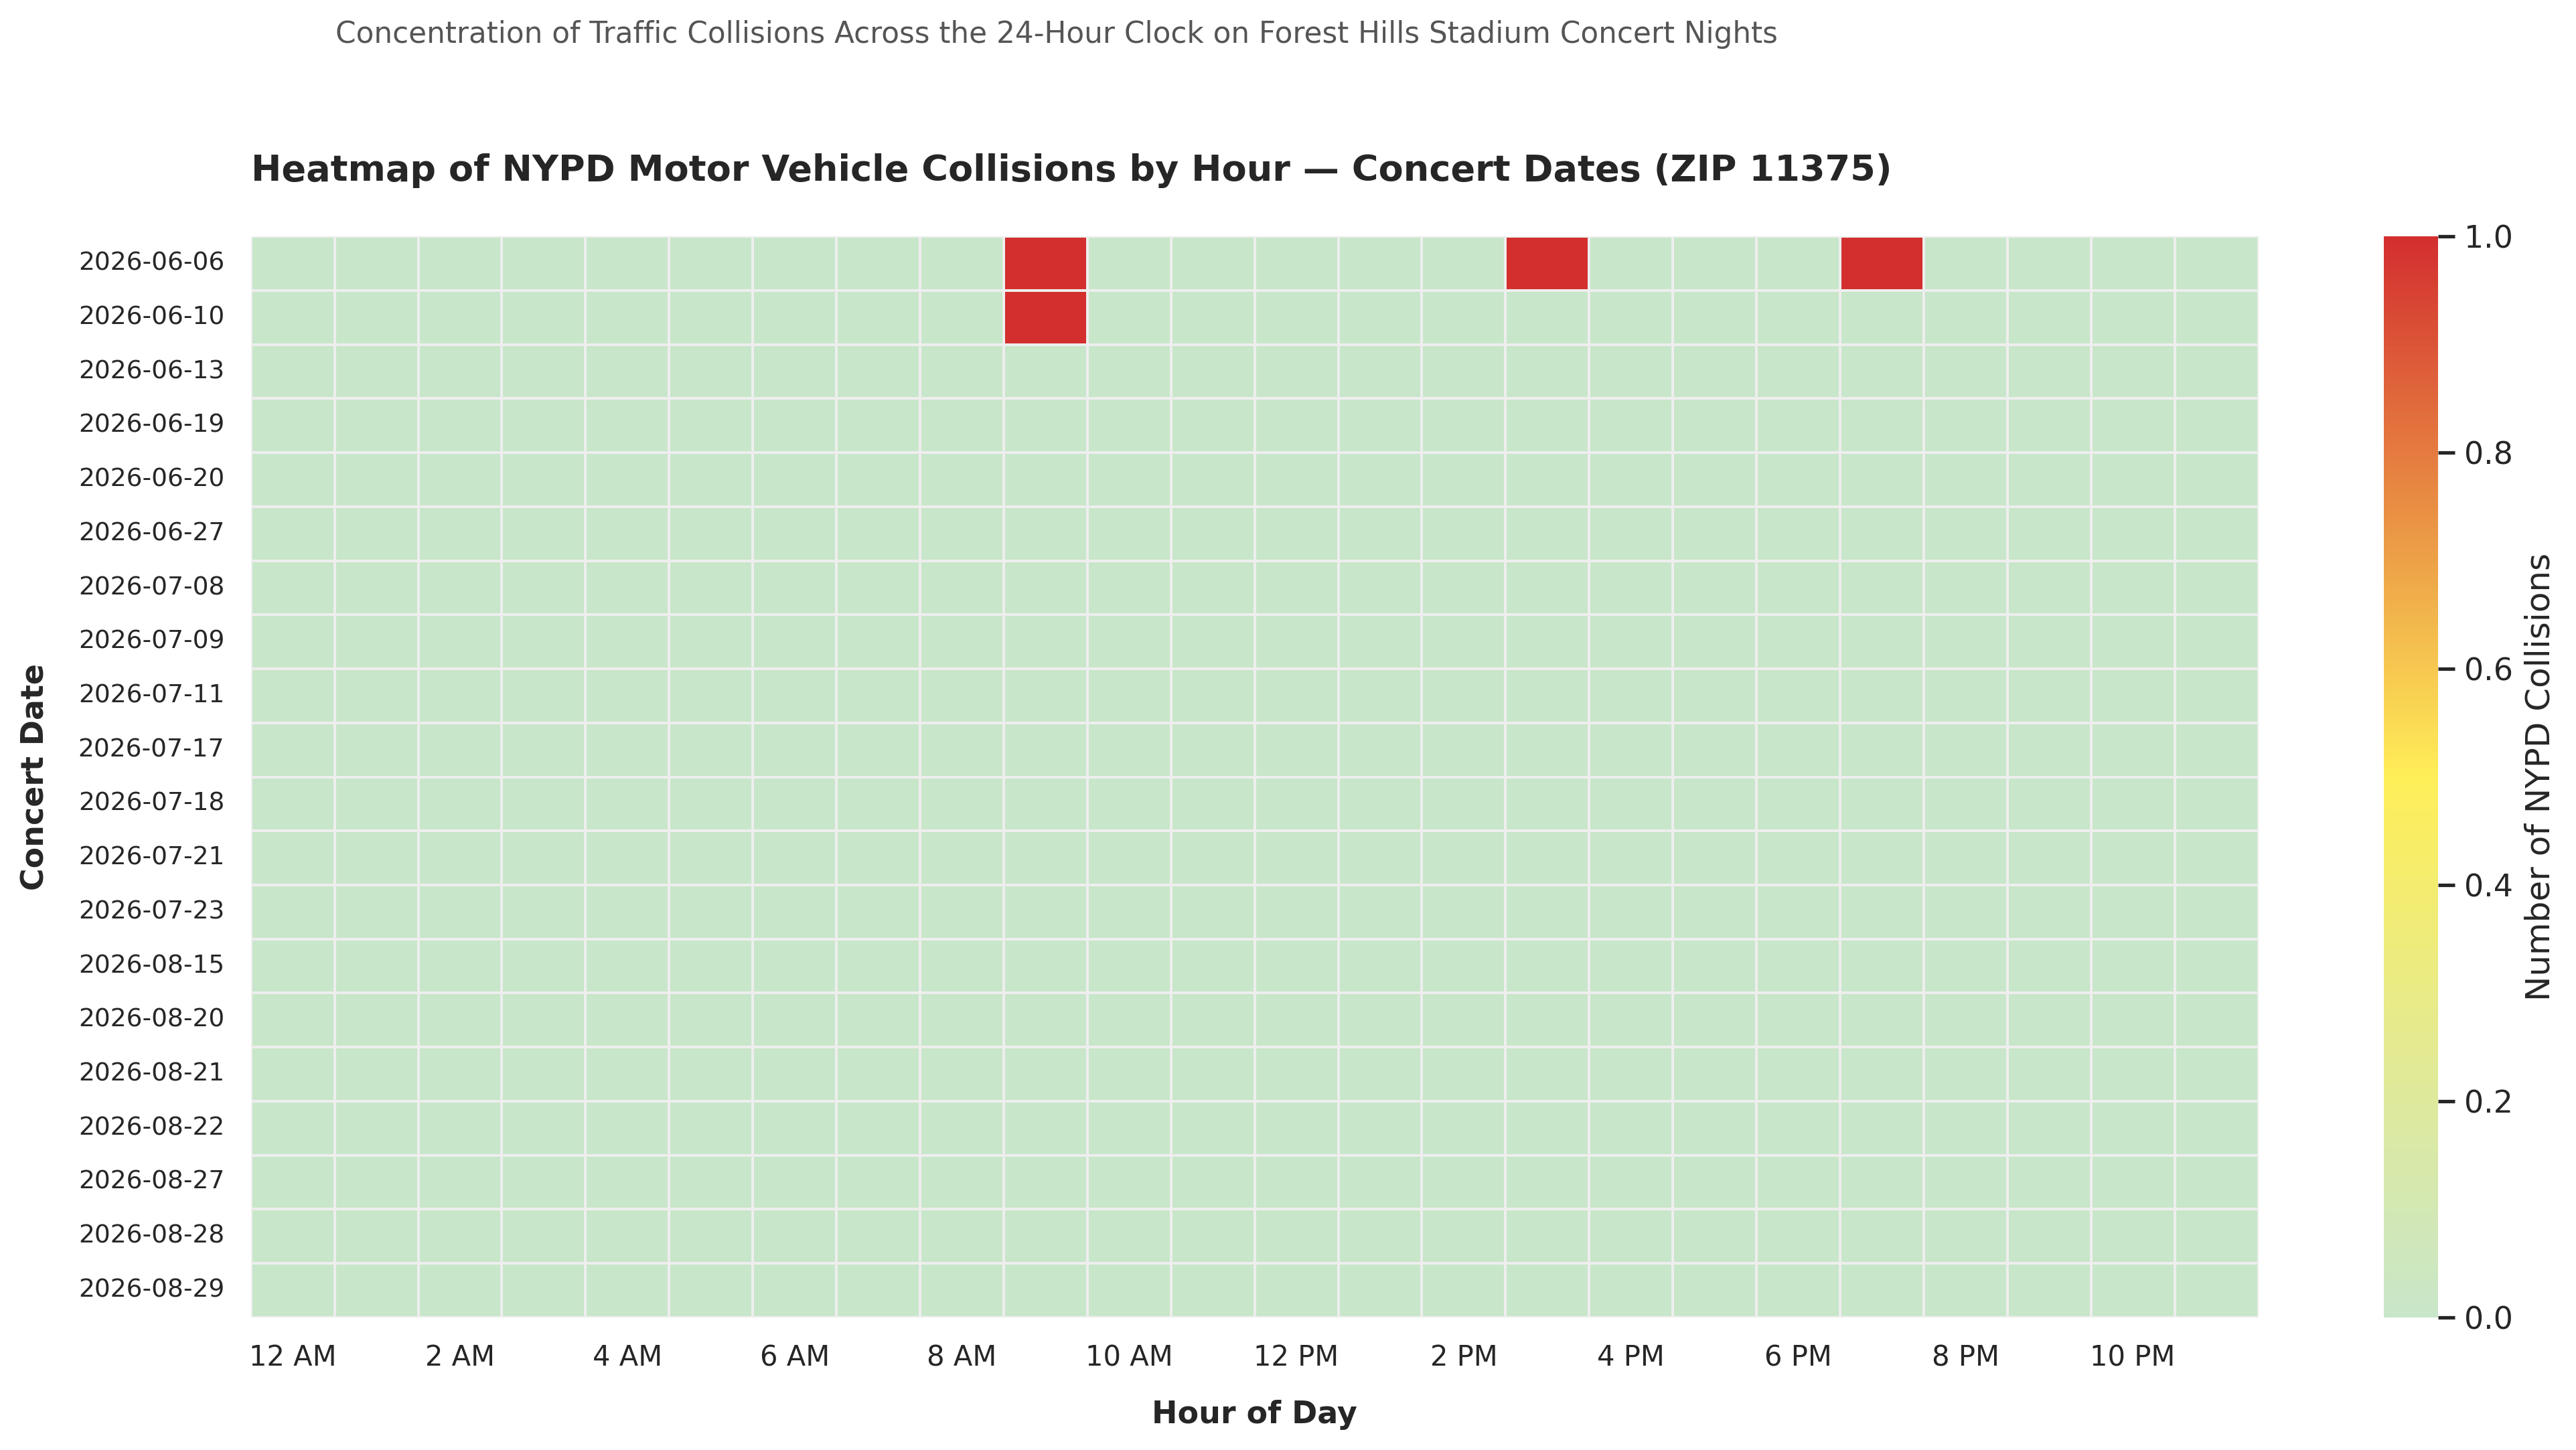

In [20]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# ==========================================
# 1. FETCH NYPD COLLISIONS FROM NYC OPEN DATA API
# ==========================================
# Socrata endpoint for NYPD Motor Vehicle Collisions
url = "https://data.cityofnewyork.us/resource/h9gi-nx95.json"

# Query for June 1, 2026 through August 31, 2026 in ZIP code 11375
where_clause = "zip_code='11375' AND crash_date >= '2026-06-01T00:00:00' AND crash_date <= '2026-08-31T23:59:59'"
params = {
    "$where": where_clause,
    "$limit": 50000,
    "$select": "collision_id, crash_date, crash_time, zip_code, latitude, longitude, number_of_persons_injured"
}

print("Fetching NYPD collision data from NYC Open Data API for ZIP 11375...")
response = requests.get(url, params=params)
data = response.json()

if not data:
    print("No collision records returned for the specified filters.")
else:
    df_crashes = pd.DataFrame(data)

    # Parse timestamps and extract date string and hour
    crash_dt = pd.to_datetime(df_crashes['crash_date'])
    df_crashes['date_str'] = crash_dt.dt.date.astype(str)

    # Extract hour from crash_time (format usually 'HH:MM')
    df_crashes['hour'] = pd.to_datetime(df_crashes['crash_time'], format='%H:%M', errors='coerce').dt.hour

    # Official 2026 Concert Dates for Forest Hills Stadium
    CONCERT_DATES = [
        # June 2026
        "2026-06-06", "2026-06-10", "2026-06-13", "2026-06-19",
        "2026-06-20", "2026-06-27",
        # July 2026
        "2026-07-08", "2026-07-09", "2026-07-11", "2026-07-17",
        "2026-07-18", "2026-07-21", "2026-07-23",
        # August 2026
        "2026-08-15", "2026-08-20", "2026-08-21", "2026-08-22",
        "2026-08-27", "2026-08-28", "2026-08-29"
    ]
    concert_set = set(CONCERT_DATES)

    # Filter strictly for concert days
    concert_crashes = df_crashes[df_crashes['date_str'].isin(concert_set)].copy()

    # Aggregate collision counts by Concert Date and Hour
    heatmap_data = concert_crashes.groupby(['date_str', 'hour']).size().reset_index(name='crash_count')

    # Create pivot table: Rows = Concert Dates, Columns = Hours (0-23)
    pivot_df = heatmap_data.pivot(index='date_str', columns='hour', values='crash_count').fillna(0)

    # Ensure all 24 hours (0-23) are present as columns
    for h in range(24):
        if h not in pivot_df.columns:
            pivot_df[h] = 0
    pivot_df = pivot_df[sorted(pivot_df.columns)]

    # Ensure all concert dates are present as rows (even if 0 crashes)
    all_concert_dates_sorted = sorted(list(concert_set))
    pivot_df = pivot_df.reindex(all_concert_dates_sorted, fill_value=0)

    # ==========================================
    # 2. PLOT HEATMAP (Light Green for Low, Red for High)
    # ==========================================
    plt.figure(figsize=(14, 8), dpi=300)
    sns.set_theme(style="white")

    # Custom colormap: Light Green -> Soft Yellow -> Dark Red
    custom_cmap = LinearSegmentedColormap.from_list(
        "lightgreen_yellow_red",
        ["#C8E6C9", "#FFEE58", "#D32F2F"]
    )

    ax = sns.heatmap(
        pivot_df,
        cmap=custom_cmap,
        linewidths=0.5,
        linecolor='#EEEEEE',
        cbar_kws={'label': 'Number of NYPD Collisions'}
    )

    plt.title("Heatmap of NYPD Motor Vehicle Collisions by Hour — Concert Dates (ZIP 11375)", fontsize=13, fontweight='bold', pad=20, loc='left')
    plt.suptitle("Concentration of Traffic Collisions Across the 24-Hour Clock on Forest Hills Stadium Concert Nights", fontsize=10.5, color='#555555', x=0.125, y=0.93, ha='left')

    plt.xlabel("Hour of Day", fontsize=11, fontweight='semibold', labelpad=10)
    plt.ylabel("Concert Date", fontsize=11, fontweight='semibold', labelpad=10)

    hour_labels = ['12 AM', '2 AM', '4 AM', '6 AM', '8 AM', '10 AM', '12 PM',
                   '2 PM', '4 PM', '6 PM', '8 PM', '10 PM']
    plt.xticks(ticks=[i + 0.5 for i in range(0, 24, 2)], labels=hour_labels, rotation=0, fontsize=10)
    plt.yticks(fontsize=9, rotation=0)

    plt.tight_layout(rect=[0, 0.03, 1, 0.91])
    plt.show()

In [19]:
import pandas as pd
import requests

# ==========================================
# 1. CONFIGURE TARGET DATES & PARAMETERS
# ==========================================
TARGET_DATES = ["2026-06-27", "2026-07-17", "2026-08-20"]
TARGET_ZIP = "11375"

# Build SoQL where clause targeting the specific dates in ZIP 11375
date_conditions = " OR ".join([f"(created_date >= '{d}T00:00:00' AND created_date <= '{d}T23:59:59')" for d in TARGET_DATES])
where_clause = f"incident_zip='{TARGET_ZIP}' AND ({date_conditions})"

url = "https://data.cityofnewyork.us/resource/erm2-nwe9.json"
params = {
    "$where": where_clause,
    "$limit": 50000,
    "$select": "unique_key, created_date, incident_zip, complaint_type"
}

print(f"Fetching 311 requests for concert dates {TARGET_DATES} in ZIP {TARGET_ZIP}...")
response = requests.get(url, params=params)
data = response.json()

# ==========================================
# 2. PROCESS AND RANK COMPLAINTS
# ==========================================
if data:
    df_311 = pd.DataFrame(data)

    # Process timestamps to isolate date and hour
    created_dt = pd.to_datetime(df_311['created_date'])
    df_311['date_str'] = created_dt.dt.date.astype(str)

    print(f"\nSuccessfully retrieved {len(df_311)} total records across the 3 dates.\n")

    # Calculate Top 10 Complaint Types across these specific dates
    top_10 = df_311['complaint_type'].value_counts().head(10)

    print("==================================================")
    print(" TOP 10 311 COMPLAINTS ON 6/27, 7/17, AND 8/20 (ZIP 11375)")
    print("==================================================")
    for idx, (complaint, count) in enumerate(top_10.items(), 1):
        print(f"{idx:2d}. {complaint:<40} | {count} calls")
    print("==================================================\n")

    # Optional: Breakdown by specific date
    print("Breakdown by individual concert date:")
    date_breakdown = df_311.groupby(['date_str', 'complaint_type']).size().reset_index(name='count')
    for d in TARGET_DATES:
        day_top = df_311[df_311['date_str'] == d]['complaint_type'].value_counts().head(3)
        print(f"\n--- Date: {d} (Total: {len(df_311[df_311['date_str'] == d])} calls) ---")
        for comp, cnt in day_top.items():
            print(f"   • {comp}: {cnt}")

else:
    print("No data returned from API for the specified dates/filters.")

Fetching 311 requests for concert dates ['2026-06-27', '2026-07-17', '2026-08-20'] in ZIP 11375...

Successfully retrieved 293 total records across the 3 dates.

 TOP 10 311 COMPLAINTS ON 6/27, 7/17, AND 8/20 (ZIP 11375)
 1. Noise - Commercial                       | 56 calls
 2. Illegal Parking                          | 36 calls
 3. Noise - Residential                      | 21 calls
 4. Noise - Street/Sidewalk                  | 14 calls
 5. Blocked Driveway                         | 14 calls
 6. Street Condition                         | 12 calls
 7. Noise                                    | 9 calls
 8. UNSANITARY CONDITION                     | 9 calls
 9. Damaged Tree                             | 9 calls
10. Encampment                               | 7 calls

Breakdown by individual concert date:

--- Date: 2026-06-27 (Total: 71 calls) ---
   • Illegal Parking: 16
   • Noise - Commercial: 16
   • Blocked Driveway: 5

--- Date: 2026-07-17 (Total: 121 calls) ---
   • Noise - Comm